# Regulating the Listening Wall: reproducibility notebook

**Paper.** Arcayan, M. A. S. *Regulating the Listening Wall: Privacy-by-Design Requirements for Intelligent Noise Control Systems in Smart Cities. A Patent, Policy, and Signal Level Study with Lessons for Korea and ASEAN.*

This notebook rebuilds every number, table, and figure in the paper that comes from data:

| Part | What it reproduces | Paper items |
|---|---|---|
| 1 | Search and screening counts, and a check that both coding sheets cover exactly the included records | Figure 1 |
| 2 | Corpus results for coder 1 (primary) and coder 2 (independent check) | Figures 2 to 5, Table B2 |
| 3 | Inter-coder reliability (agreement, Cohen's kappa with bootstrap CI, Gwet's AC1) and the disagreement log | Table B1 |
| 4 | Experiments A, B, and C on open speech and urban sound data | Figures 7 to 9, Tables 6 and 7 |
| 5 | The control framework diagram | Figure 6 |
| 6 | Every number quoted in the text, and a check against the values printed in the paper | All |

**How to run.** In Google Colab choose *Runtime > Run all*. The first cell installs the exact library versions used for the paper. If any version differs, the runtime restarts once; then choose *Run all* again. With `RECOMPUTE_EXPERIMENTS = True` the full run takes about one hour on a standard Colab CPU runtime, mostly for Experiment A. Set it to `False` to rebuild the figures from the cached experiment results in a few minutes.

**Data.** The corpus files are in `data/corpus/`. They hold the records that passed screening (260 articles and 392 patents) and the coding sheets of both coders. The audio comes from two public datasets, downloaded at fixed commits: ESC-50 (CC BY-NC 3.0) and MS-SNSD (MIT License). A manifest with SHA-256 checksums confirms that the exact audio files used in the paper are read. Full texts and abstracts of the research articles are not shared because of publisher copyright; bibliographic records and DOIs are given instead.

**Coders.** Coder 1 is the author. Coder 2 is an AI-assisted coder (Claude, Anthropic) who coded every record independently and blind to coder 1's codes, using the codebook in `docs/codebook.md`. The procedure is described in `docs/coding_procedure.md`.

## 0. Settings and environment

In [1]:
# ---- Settings you may change -------------------------------------------------
RECOMPUTE_EXPERIMENTS = True   # False = use cached results in data/experiments/ (fast)
N_JOBS = 2                     # parallel processes for the experiments (Colab CPU has 2)
REPO_URL = "https://github.com/Mark040297/listening-wall.git"   # <- set after you upload the repository
ESC50_COMMIT = "33c8ce9eb2cf0b1c2f8bcf322eb349b6be34dbb6"
MSSNSD_COMMIT = "fe61c4ba0d9ac8dd7e23d719cc79f8947e1dc742"

In [2]:
# ---- Pinned library versions (the versions used to produce the paper) -------
import os, sys, subprocess, importlib.metadata as md

PINS = {"numpy": "2.5.3", "scipy": "1.18.1", "pandas": "3.0.5", "matplotlib": "3.11.2",
        "scikit-learn": "1.9.1", "librosa": "1.0.0", "soundfile": "0.14.0", "pystoi": "0.4.1",
        "numba": "0.68.0"}


def _version(p):
    try:
        return md.version(p)
    except md.PackageNotFoundError:
        return None


print("Python", sys.version.split()[0])
if sys.version_info < (3, 12):
    print("Warning: the pinned versions need Python 3.12 or newer.")
_need = {p: v for p, v in PINS.items() if _version(p) != v}
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ
if _need:
    print("Installing pinned versions:", _need)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + [f"{p}=={v}" for p, v in PINS.items()], check=True)
    if IN_COLAB:
        print("Done. The runtime restarts now. When it reconnects, choose Runtime > Run all again.")
        os.kill(os.getpid(), 9)
    raise SystemExit("Pinned versions installed. Restart the kernel and run all cells again.")
for p in PINS:
    print(f"  {p:13s} {_version(p)}")

Python 3.12.13
  numpy         2.5.3
  scipy         1.18.1
  pandas        3.0.5
  matplotlib    3.11.2
  scikit-learn  1.9.1
  librosa       1.0.0
  soundfile     0.14.0
  pystoi        0.4.1
  numba         0.68.0


In [3]:
# ---- Locate or download the repository data ----------------------------------
from pathlib import Path

if Path("data/corpus").exists():
    ROOT = Path(".").resolve()
elif Path("listening-wall/data/corpus").exists():
    ROOT = Path("listening-wall").resolve()
else:
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "listening-wall"], check=True)
    ROOT = Path("listening-wall").resolve()
CORPUS = ROOT / "data" / "corpus"
EXPDIR = ROOT / "data" / "experiments"
EXTERNAL = ROOT / "external"
FIG = ROOT / "figures"
TAB = ROOT / "tables"
RES = ROOT / "results"
for d in (FIG, TAB, RES, EXTERNAL):
    d.mkdir(exist_ok=True)
print("Repository root:", ROOT)

Repository root: /content/listening-wall


In [4]:
# ---- Imports and the common figure style of the paper -----------------------
import json, re, glob, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import Image, display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID = "#1a1a1a", "#52514e", "#d9d8d4"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9, "axes.edgecolor": INK2,
                     "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.spines.top": False, "axes.spines.right": False})
PV = {}   # every number quoted in the paper is collected here (Part 6)


def save(fig, name, width=None):
    """Save at 300 dpi exactly as used in the paper, then show the saved file."""
    path = FIG / name
    fig.savefig(path, dpi=300, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    display(Image(filename=str(path), width=width or 760))


def norm_title(s):
    return re.sub(r"[^a-z0-9]", "", str(s).lower())


def pct(k, n):
    return 100.0 * k / n


def r2(v):
    """Two decimals without a negative zero."""
    s = f"{v:.2f}"
    return "0.00" if s == "-0.00" else s

## Part 1. Search, screening, and the included records (Figure 1)

The searches and the screening were done before coding. Their exports are not part of this repository, so the counts in Figure 1 are those recorded in the author's search records. The search strategy is given in the paper (Section 3.2 and Table A1):

* **Articles.** Scopus, Web of Science, IEEE Xplore, and Google Scholar; publication years 2015 to 2025; keyword combinations from five concept groups: acoustic metamaterials, active noise control, adaptive or intelligent systems, machine learning and artificial intelligence, and smart city applications with cloud or IoT technology.
* **Patents.** KIPRIS, two queries: `"acoustic metamaterial" *AD=[20150101~20251231]` and `"active noise control" *AD=[20150101~20251231]`. `AD` is the application date and `*` joins two conditions with AND.

The repository holds the records that passed screening: `articles_included.csv` (260 articles) and `patents_included.csv` (392 patents). Every analysis starts from these two files. The cell below checks that both coding sheets cover exactly these records.

Included records: 260 articles and 392 patents. Both coding sheets cover exactly these records.

Included patents by office (KIPRIS office code):
code                 office  patents
  US          United States      157
  EP European Patent Office       67
  WO             WIPO (PCT)       59
  JP                  Japan       42
  KR                  Korea       33
  CN                  China       17
  TA                 Taiwan        8
  IN                  India        6
  RU                 Russia        1
  CA                 Canada        1
  ES                  Spain        1


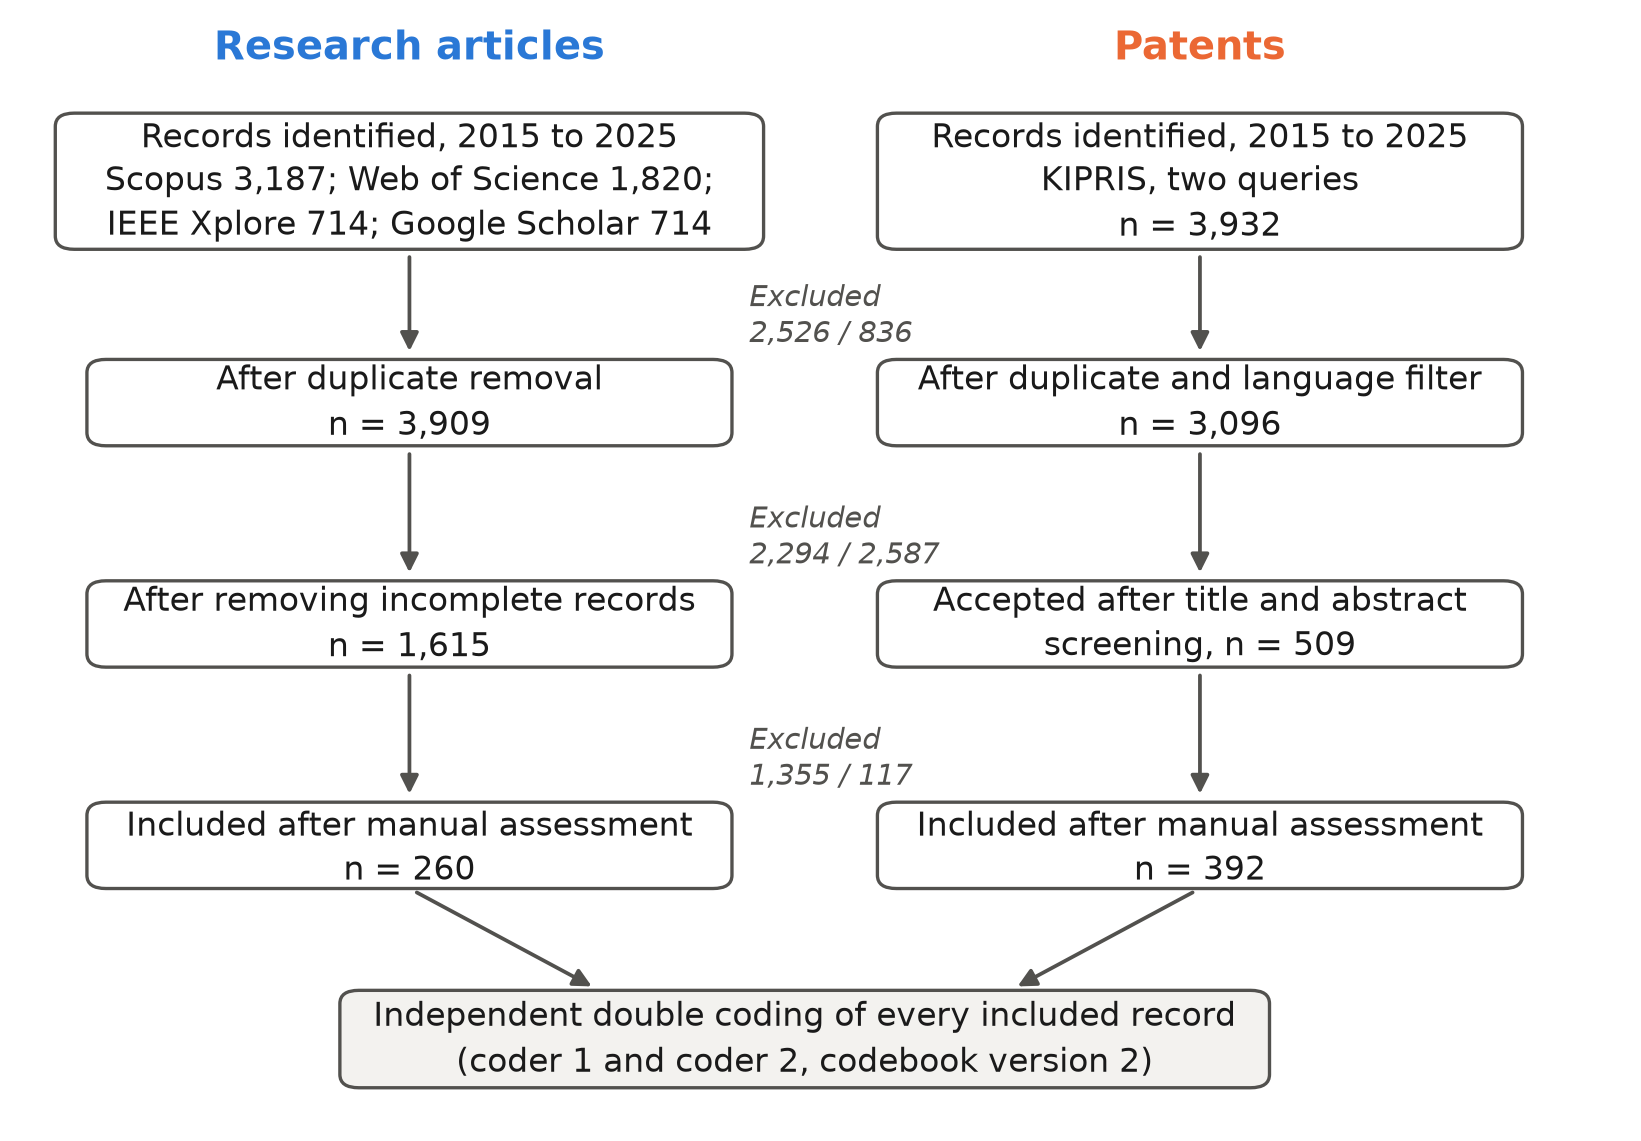

In [5]:
ART_SEARCH = {"Scopus": 3187, "Web of Science": 1820, "IEEE Xplore": 714, "Google Scholar": 714}
ART_DEDUP, ART_COMPLETE = 3909, 1615
PAT_IDENTIFIED, PAT_DEDUP, PAT_ACCEPTED = 3932, 3096, 509
# patent offices of the 3,932 KIPRIS records: 17 offices, the six largest listed here
N_OFFICES_SEARCH = 17
PAT_SEARCH_OFFICES = {"US": 1408, "CN": 804, "WO": 535, "KR": 442, "EP": 412, "JP": 252}

arts = pd.read_csv(CORPUS / "articles_included.csv", dtype=str)
pats = pd.read_csv(CORPUS / "patents_included.csv", dtype={"id": str})
c1a_raw = pd.read_csv(CORPUS / "coder1_articles.csv", dtype=str)
c1p_raw = pd.read_csv(CORPUS / "coder1_patents.csv", dtype=str)
c2a_ids = pd.read_csv(CORPUS / "coder2_articles.csv", dtype=str).id.str.strip()
c2p_ids = pd.read_csv(CORPUS / "coder2_patents.csv", dtype=str).id.str.strip()
N_ART, N_PAT = len(arts), len(pats)
assert arts.id.is_unique and pats.id.is_unique
assert list(c1a_raw.ID.str.strip()) == list(arts.id) and len(c2a_ids) == N_ART and set(c2a_ids) == set(arts.id)
assert list(c1p_raw.PATENT_ID.str.strip()) == list(pats.id) and len(c2p_ids) == N_PAT and set(c2p_ids) == set(pats.id)
print(f"Included records: {N_ART} articles and {N_PAT} patents. Both coding sheets cover exactly these records.")

OFF_NAME = {"US": "United States", "EP": "European Patent Office", "WO": "WIPO (PCT)", "JP": "Japan", "KR": "Korea",
            "CN": "China", "TA": "Taiwan", "IN": "India", "RU": "Russia", "CA": "Canada", "ES": "Spain"}
off = pats.office.value_counts()
print("\nIncluded patents by office (KIPRIS office code):")
print(pd.DataFrame({"code": off.index, "office": [OFF_NAME.get(k, k) for k in off.index], "patents": off.values}).to_string(index=False))
PV.update(A_IDENTIFIED=sum(ART_SEARCH.values()), A_DEDUP=ART_DEDUP, A_COMPLETE=ART_COMPLETE, A_INCLUDED=N_ART,
          P_RAW=PAT_IDENTIFIED, P_SCREENED=PAT_DEDUP, P_ACCEPTED=PAT_ACCEPTED, P_N_OFFICES_SEARCH=N_OFFICES_SEARCH,
          P_N_OFFICES=int(len(off)))
for k, v in PAT_SEARCH_OFFICES.items():
    PV[f"P_SEARCH_{k}"] = v
for k, v in off.items():
    PV[f"P_OFF_{k}"] = int(v)

fig, ax = plt.subplots(figsize=(6.8, 4.6))
ax.set_xlim(0, 100); ax.set_ylim(4, 100); ax.axis("off")


def box(x, y, w, h, text, fc="#ffffff"):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.4,rounding_size=1.2",
                                fc=fc, ec=INK2, lw=0.8))
    ax.text(x, y, text, ha="center", va="center", fontsize=7.9, color=INK, linespacing=1.35)


def arrow(x0, y0, x1, y1):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", color=INK2, lw=0.9))


def note(x, y, t):
    ax.text(x, y, t, ha="left", va="center", fontsize=7.0, color=INK2, style="italic", linespacing=1.3)


ax.text(24, 99, "Research articles", ha="center", fontsize=9.5, fontweight="bold", color=BLUE)
ax.text(74, 99, "Patents", ha="center", fontsize=9.5, fontweight="bold", color=ORANGE)
box(24, 88, 44, 11.5, "Records identified, 2015 to 2025\nScopus 3,187; Web of Science 1,820;\nIEEE Xplore 714; Google Scholar 714")
box(74, 88, 40, 11.5, f"Records identified, 2015 to 2025\nKIPRIS, two queries\nn = {PAT_IDENTIFIED:,}")
box(24, 68, 40, 7, f"After duplicate removal\nn = {ART_DEDUP:,}")
box(74, 68, 40, 7, f"After duplicate and language filter\nn = {PAT_DEDUP:,}")
box(24, 48, 40, 7, f"After removing incomplete records\nn = {ART_COMPLETE:,}")
box(74, 48, 40, 7, f"Accepted after title and abstract\nscreening, n = {PAT_ACCEPTED}")
box(24, 28, 40, 7, f"Included after manual assessment\nn = {N_ART}")
box(74, 28, 40, 7, f"Included after manual assessment\nn = {N_PAT}")
for x in (24, 74):
    arrow(x, 81.9, x, 71.9); arrow(x, 64.1, x, 51.9); arrow(x, 44.1, x, 31.9)
note(45.5, 76, f"Excluded\n{sum(ART_SEARCH.values()) - ART_DEDUP:,} / {PAT_IDENTIFIED - PAT_DEDUP:,}")
note(45.5, 56, f"Excluded\n{ART_DEDUP - ART_COMPLETE:,} / {PAT_DEDUP - PAT_ACCEPTED:,}")
note(45.5, 36, f"Excluded\n{ART_COMPLETE - N_ART:,} / {PAT_ACCEPTED - N_PAT}")
box(49, 10.5, 58, 8, "Independent double coding of every included record\n(coder 1 and coder 2, codebook version 2)", fc="#f3f2ef")
arrow(24, 24.1, 36, 14.9); arrow(74, 24.1, 62, 14.9)
save(fig, "figure1_flow.png")

## Part 2. Corpus results (Figures 2 to 5)

### 2.1 Reading the two coding sheets

Both coding sheets use the value lists of the codebook (`docs/codebook.md`). The original sheet of coder 1 used a few other labels and had one column slip. Before publication these were cleaned with fixed rules, and `data/corpus/coder1_cleaning_log.csv` lists every changed cell with its original value and the rule applied:

* R1: continuous sensing `adaptive` is recorded as yes, because an adaptive controller runs on a live microphone signal;
* R2: processing domain `not_specified` is recorded as unclear (one category in the codebook);
* R3: setting `headphones` is recorded as personal_wearable; R4: any other setting label outside the codebook list is recorded as other;
* R5: for 47 patents the processing location cell repeated the deployment setting label, so no processing location was recorded; these cells are recorded as not_specified;
* R6: coder 1 could not open the file of one article (RA33); its cells are recorded as not_coded. It counts as showing none of the features in the shares of coder 1 and is left out of the reliability comparison;
* R7: patent year is the application year of the search record (4 patents); R8: spelling of one column name.

One variable is derived here: for articles, speech classification is yes when the classification classes of coder 1 name speech or voice. For patents, coder 1 coded speech classification after the main round (column `SPEECH_CLASSIFICATION`). Speech classification is part of sound classification, so the 337 patents without sound classification are no. Coder 1 judged the other 55 from the title and abstract. Because this variable was coded after the main round, it is not used in the reliability comparison for patents.

The binary indicators used in the paper are: continuous sensing = yes; AI or ML = yes; network = yes; sound classification = yes; speech classification = yes; cloud processing = cloud_only or hybrid; frequency domain processing = frequency_domain or time_frequency.

In [6]:
SETS = ["building_interior", "building_exterior", "vehicle_interior", "personal_wearable", "residential_home",
        "outdoor_urban", "outdoor_industrial", "laboratory_only", "not_specified"]
ALLOWED = {"continuous_sensing": {"yes", "no", "unclear"}, "ai_ml": {"yes", "no", "unclear"},
           "network": {"yes", "no", "unclear"}, "sound_classification": {"yes", "no", "unclear"},
           "speech_classification": {"yes", "no"},
           "processing_location": {"local_only", "cloud_only", "hybrid", "not_specified"},
           "processing_domain": {"time_domain", "frequency_domain", "time_frequency", "unclear"},
           "deployment_setting": set(SETS)}


def _s(x):
    return x.astype(str).str.strip().str.lower()


def check(d, extra=()):
    for c, ok in ALLOWED.items():
        bad = set(d[c]) - ok - set(extra)
        assert not bad, (c, bad)


def coder1_articles():
    r = c1a_raw
    d = pd.DataFrame({"id": r.ID.str.strip(), "year": r.YEAR.astype(int)})
    d["continuous_sensing"] = _s(r.ALWAYS_ON_SENSING)
    d["ai_ml"] = _s(r.USES_AI_OR_ML)
    d["network"] = _s(r.HAS_NETWORK_CONNECTIVITY)
    d["sound_classification"] = _s(r.SOUND_CLASSIFICATION)
    cls = _s(r.CLASSIFICATION_CLASSES)
    d["speech_classification"] = np.where(cls == "not_coded", "not_coded", np.where(cls.str.contains("speech|voice"), "yes", "no"))
    d["processing_location"] = _s(r.PROCESSING_LOCATION)
    d["processing_domain"] = _s(r.PROCESSING_DOMAIN)
    d["deployment_setting"] = _s(r.DEPLOYMENT_SETTING)
    check(d, extra=("not_coded", "other"))
    return d


def coder1_patents():
    p = c1p_raw
    d = pd.DataFrame({"id": p.PATENT_ID.str.strip(), "year": p.YEAR.astype(int)})
    assert (d.year.values == pats.year.astype(int).values).all()
    d["continuous_sensing"] = _s(p.ALWAYS_ON_SENSING)
    d["ai_ml"] = _s(p.USES_AI_OR_ML)
    d["network"] = _s(p.HAS_NETWORK_CONNECTIVITY)
    d["sound_classification"] = _s(p.SOUND_CLASSIFICATION)
    d["speech_classification"] = _s(p.SPEECH_CLASSIFICATION)
    d["processing_location"] = _s(p.PROCESSING_LOCATION)
    d["processing_domain"] = _s(p.PROCESSING_DOMAIN)
    d["deployment_setting"] = _s(p.DEPLOYMENT_SETTING)
    check(d, extra=("not_coded", "other"))
    return d


def coder2(kind, ids, years):
    d = pd.read_csv(CORPUS / f"coder2_{kind}.csv", dtype=str)
    d["id"] = d.id.str.strip()
    for c in d.columns:
        if c not in ("id", "note", "round"):
            d[c] = _s(d[c])
    d = d.set_index("id").loc[ids].reset_index()
    d.insert(1, "year", years)
    check(d)
    return d


A1 = coder1_articles()
P1 = coder1_patents()
A2 = coder2("articles", A1.id.values, A1.year.values)
P2 = coder2("patents", P1.id.values, P1.year.values)
log = pd.read_csv(CORPUS / "coder1_cleaning_log.csv")
PV["P_R5_N"] = int(((log.corpus == "patents") & (log.rule == "R5")).sum())
print("articles", len(A1), len(A2), " patents", len(P1), len(P2))
print("Cells cleaned in the sheets of coder 1, by rule:")
print(log.groupby(["corpus", "rule"]).size().to_string())

FEAT = {"continuous": ("continuous_sensing", lambda v: v == "yes"),
        "ai": ("ai_ml", lambda v: v == "yes"),
        "network": ("network", lambda v: v == "yes"),
        "sound_cls": ("sound_classification", lambda v: v == "yes"),
        "speech_cls": ("speech_classification", lambda v: v == "yes"),
        "cloud": ("processing_location", lambda v: v.isin(["cloud_only", "hybrid"])),
        "freq": ("processing_domain", lambda v: v.isin(["frequency_domain", "time_frequency"]))}


def indicators(d):
    return pd.DataFrame({k: f(d[c]).values for k, (c, f) in FEAT.items()}, index=d.id)


IA1, IA2, IP1, IP2 = (indicators(d) for d in (A1, A2, P1, P2))

articles 260 260  patents 392 392
Cells cleaned in the sheets of coder 1, by rule:
corpus    rule
articles  R1      163
          R2        8
          R3        1
          R4        2
          R6       19
          R8        1
patents   R5       47
          R7        4


### 2.2 Prevalence of privacy-relevant capabilities under both coders (Table B2)

In [7]:
LABELS = {"continuous": "Continuous sensing", "ai": "AI or ML", "network": "Network connectivity",
          "sound_cls": "Sound classification", "speech_cls": "Speech classification",
          "cloud": "Cloud or hybrid processing", "freq": "Frequency domain processing"}
rows = []
for k, lab in LABELS.items():
    r = {"Capability": lab}
    for name, I, n in [("Articles, coder 1", IA1, N_ART), ("Articles, coder 2", IA2, N_ART),
                       ("Patents, coder 1", IP1, N_PAT), ("Patents, coder 2", IP2, N_PAT)]:
        r[name] = f"{int(I[k].sum())} ({pct(I[k].sum(), n):.1f})"
    rows.append(r)
tabB2 = pd.DataFrame(rows)
tabB2.to_csv(TAB / "tableB2_capabilities_both_coders.csv", index=False)
print(f"n = {N_ART} articles and {N_PAT} patents; cells give count (percent)")
display(tabB2)
for tag, I, n in [("A1", IA1, N_ART), ("A2", IA2, N_ART), ("P1", IP1, N_PAT), ("P2", IP2, N_PAT)]:
    for k in LABELS:
        PV[f"{tag}_{k.upper()}_N"] = int(I[k].sum())
        PV[f"{tag}_{k.upper()}_PCT"] = round(pct(I[k].sum(), n), 1)
both = pd.concat([IA1.continuous, IP1.continuous])
PV["ALL1_CONTINUOUS_N"] = int(both.sum()); PV["ALL_N"] = len(both); PV["ALL1_CONTINUOUS_PCT"] = round(pct(both.sum(), len(both)), 1)
both2 = pd.concat([IA2.continuous, IP2.continuous])
PV["ALL2_CONTINUOUS_N"] = int(both2.sum()); PV["ALL2_CONTINUOUS_PCT"] = round(pct(both2.sum(), len(both2)), 1)
PV["N_ART"], PV["N_PAT"] = N_ART, N_PAT

n = 260 articles and 392 patents; cells give count (percent)


,Capability,"Articles, coder 1","Articles, coder 2","Patents, coder 1","Patents, coder 2"
0,Continuous sensing,177 (68.1),224 (86.2),314 (80.1),357 (91.1)
1,AI or ML,83 (31.9),81 (31.2),48 (12.2),33 (8.4)
2,Network connectivity,45 (17.3),54 (20.8),29 (7.4),33 (8.4)
3,Sound classification,40 (15.4),36 (13.8),50 (12.8),46 (11.7)
4,Speech classification,27 (10.4),11 (4.2),7 (1.8),16 (4.1)
5,Cloud or hybrid processing,9 (3.5),6 (2.3),11 (2.8),3 (0.8)
6,Frequency domain processing,79 (30.4),75 (28.8),172 (43.9),33 (8.4)


### 2.3 Growth of the field (Figure 2)

Cumulative counts by publication year (articles) and application year (patents, from the search record). The dashed lines count records with AI or ML, network connectivity, or cloud processing (coder 1).

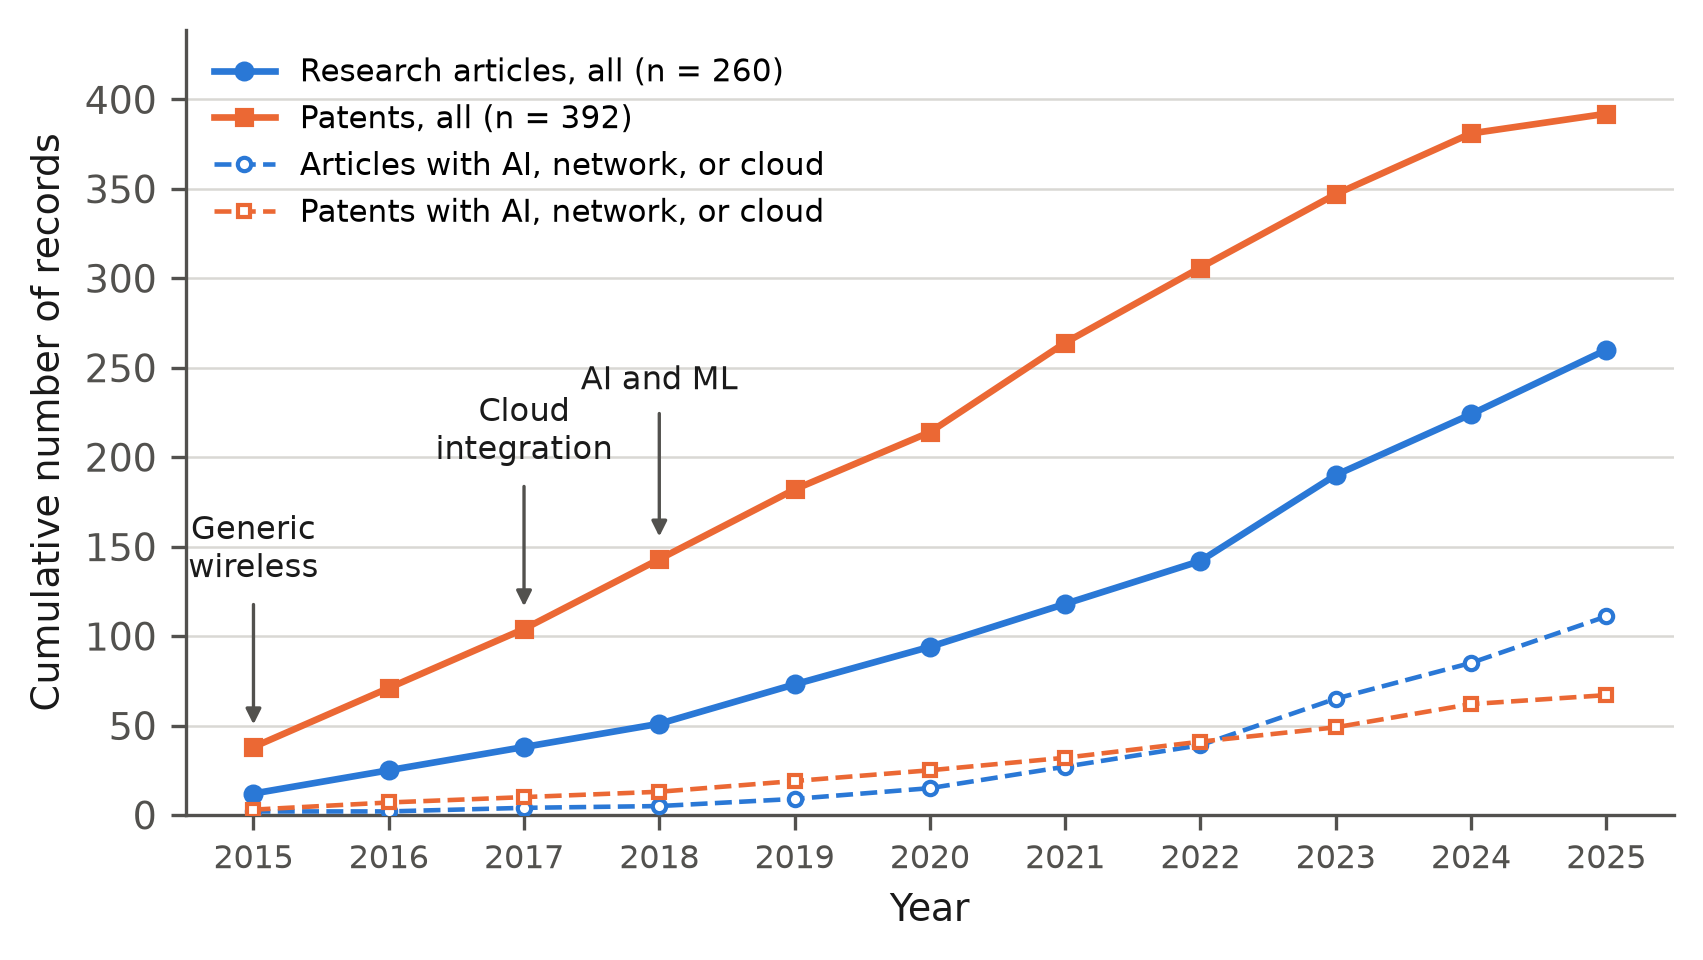

 year  articles  patents  articles_ai_net_cloud  patents_ai_net_cloud
 2015        12       38                      2                     3
 2016        25       71                      2                     7
 2017        38      104                      4                    10
 2018        51      143                      5                    13
 2019        73      182                      9                    19
 2020        94      214                     15                    25
 2021       118      264                     27                    32
 2022       142      306                     39                    41
 2023       190      347                     65                    49
 2024       224      381                     85                    62
 2025       260      392                    111                    67


In [8]:
years = np.arange(2015, 2026)


def cum(d, I, mask=None):
    y = d.year.values if mask is None else d.year.values[mask]
    return np.array([(y <= t).sum() for t in years])


adv_a = (IA1.ai | IA1.network | IA1.cloud).values
adv_p = (IP1.ai | IP1.network | IP1.cloud).values
ca, cp = cum(A1, IA1), cum(P1, IP1)
caa, cpa = cum(A1, IA1, adv_a), cum(P1, IP1, adv_p)
PV.update(A_ADV_2025=int(caa[-1]), P_ADV_2025=int(cpa[-1]))
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.plot(years, ca, "-o", color=BLUE, ms=3.8, lw=1.6, label=f"Research articles, all (n = {N_ART})", zorder=3)
ax.plot(years, cp, "-s", color=ORANGE, ms=3.6, lw=1.6, label=f"Patents, all (n = {N_PAT})", zorder=3)
ax.plot(years, caa, "--o", color=BLUE, ms=3.2, lw=1.1, mfc="white", label="Articles with AI, network, or cloud", zorder=3)
ax.plot(years, cpa, "--s", color=ORANGE, ms=3.0, lw=1.1, mfc="white", label="Patents with AI, network, or cloud", zorder=3)
for x, t in [(2015, "Generic\nwireless"), (2017, "Cloud\nintegration"), (2018, "AI and ML")]:
    ax.annotate(t, xy=(x, cp[x - 2015] + 8), xytext=(x, cp[x - 2015] + 95), ha="center", fontsize=7.6, color=INK,
                arrowprops=dict(arrowstyle="-|>", color=INK2, lw=0.8))
ax.set_xticks(years); ax.set_xticklabels(years, fontsize=7.6)
ax.set_xlabel("Year"); ax.set_ylabel("Cumulative number of records")
ax.set_ylim(0, max(cp.max(), ca.max()) * 1.12)
ax.yaxis.grid(True, color=GRID, lw=0.6, zorder=0)
ax.legend(frameon=False, fontsize=7.4, loc="upper left")
save(fig, "figure2_growth.png")
print(pd.DataFrame({"year": years, "articles": ca, "patents": cp, "articles_ai_net_cloud": caa, "patents_ai_net_cloud": cpa}).to_string(index=False))

### 2.4 Capabilities (Figure 3)

Bars show coder 1, the primary coding. Black diamonds show coder 2 for the same records.

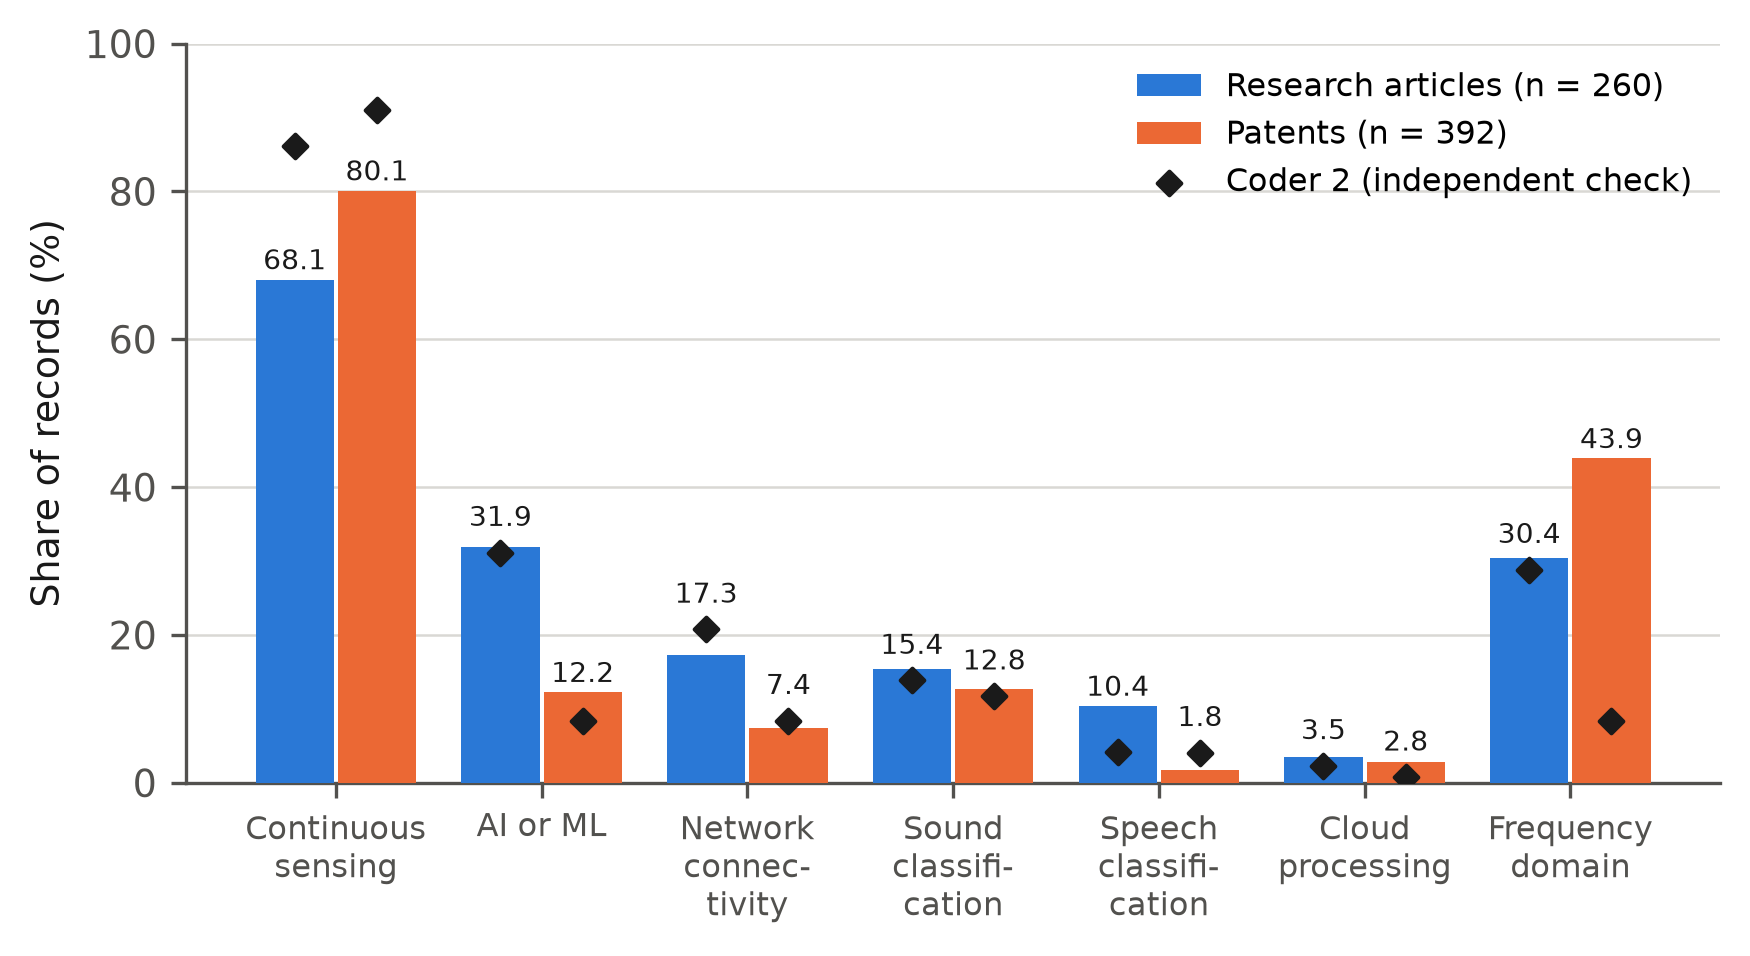

In [9]:
caps = ["continuous", "ai", "network", "sound_cls", "speech_cls", "cloud", "freq"]
caplab = ["Continuous\nsensing", "AI or ML", "Network\nconnec-\ntivity", "Sound\nclassifi-\ncation", "Speech\nclassifi-\ncation",
          "Cloud\nprocessing", "Frequency\ndomain"]
pa1 = np.array([pct(IA1[k].sum(), N_ART) for k in caps]); pa2 = np.array([pct(IA2[k].sum(), N_ART) for k in caps])
pp1 = np.array([pct(IP1[k].sum(), N_PAT) for k in caps]); pp2 = np.array([pct(IP2[k].sum(), N_PAT) for k in caps])
fig, ax = plt.subplots(figsize=(6.6, 3.2))
x = np.arange(len(caps)); w = 0.38
b1 = ax.bar(x - w / 2 - 0.01, pa1, w, color=BLUE, label=f"Research articles (n = {N_ART})", zorder=3)
b2 = ax.bar(x + w / 2 + 0.01, pp1, w, color=ORANGE, label=f"Patents (n = {N_PAT})", zorder=3)
d2 = ax.scatter(x - w / 2 - 0.01, pa2, marker="D", s=16, color=INK, zorder=4, label="Coder 2 (independent check)")
ax.scatter(x + w / 2 + 0.01, pp2, marker="D", s=16, color=INK, zorder=4)
for bars, vals, v2s in [(b1, pa1, pa2), (b2, pp1, pp2)]:
    for r, v, v2 in zip(bars, vals, v2s):
        top = max(v, v2 + 2.2 if abs(v2 - v) < 4.5 else 0)
        ax.text(r.get_x() + r.get_width() / 2, top + 1.4, f"{v:.1f}", ha="center", fontsize=6.8, color=INK)
ax.set_xticks(x); ax.set_xticklabels(caplab, fontsize=7.6)
ax.set_ylabel("Share of records (%)"); ax.set_ylim(0, 100)
ax.yaxis.grid(True, color=GRID, lw=0.6, zorder=0)
ax.legend(handles=[b1, b2, d2], frameon=False, fontsize=7.6, loc="upper right")
save(fig, "figure3_capabilities.png")

### 2.5 Deployment settings (Figure 4)

,Setting,"Articles, coder 1","Articles, coder 2","Patents, coder 1","Patents, coder 2"
0,Building interior,53,20,28,18
1,Vehicle interior,30,10,122,109
2,Personal wearable,38,36,95,77
3,Outdoor industrial,28,22,14,10
4,Outdoor urban,20,15,3,11
5,Building exterior,12,0,4,3
6,Residential home,4,10,1,3
7,Laboratory only,31,137,0,0
8,Not specified,41,10,125,161
9,Other or not coded,3,0,0,0


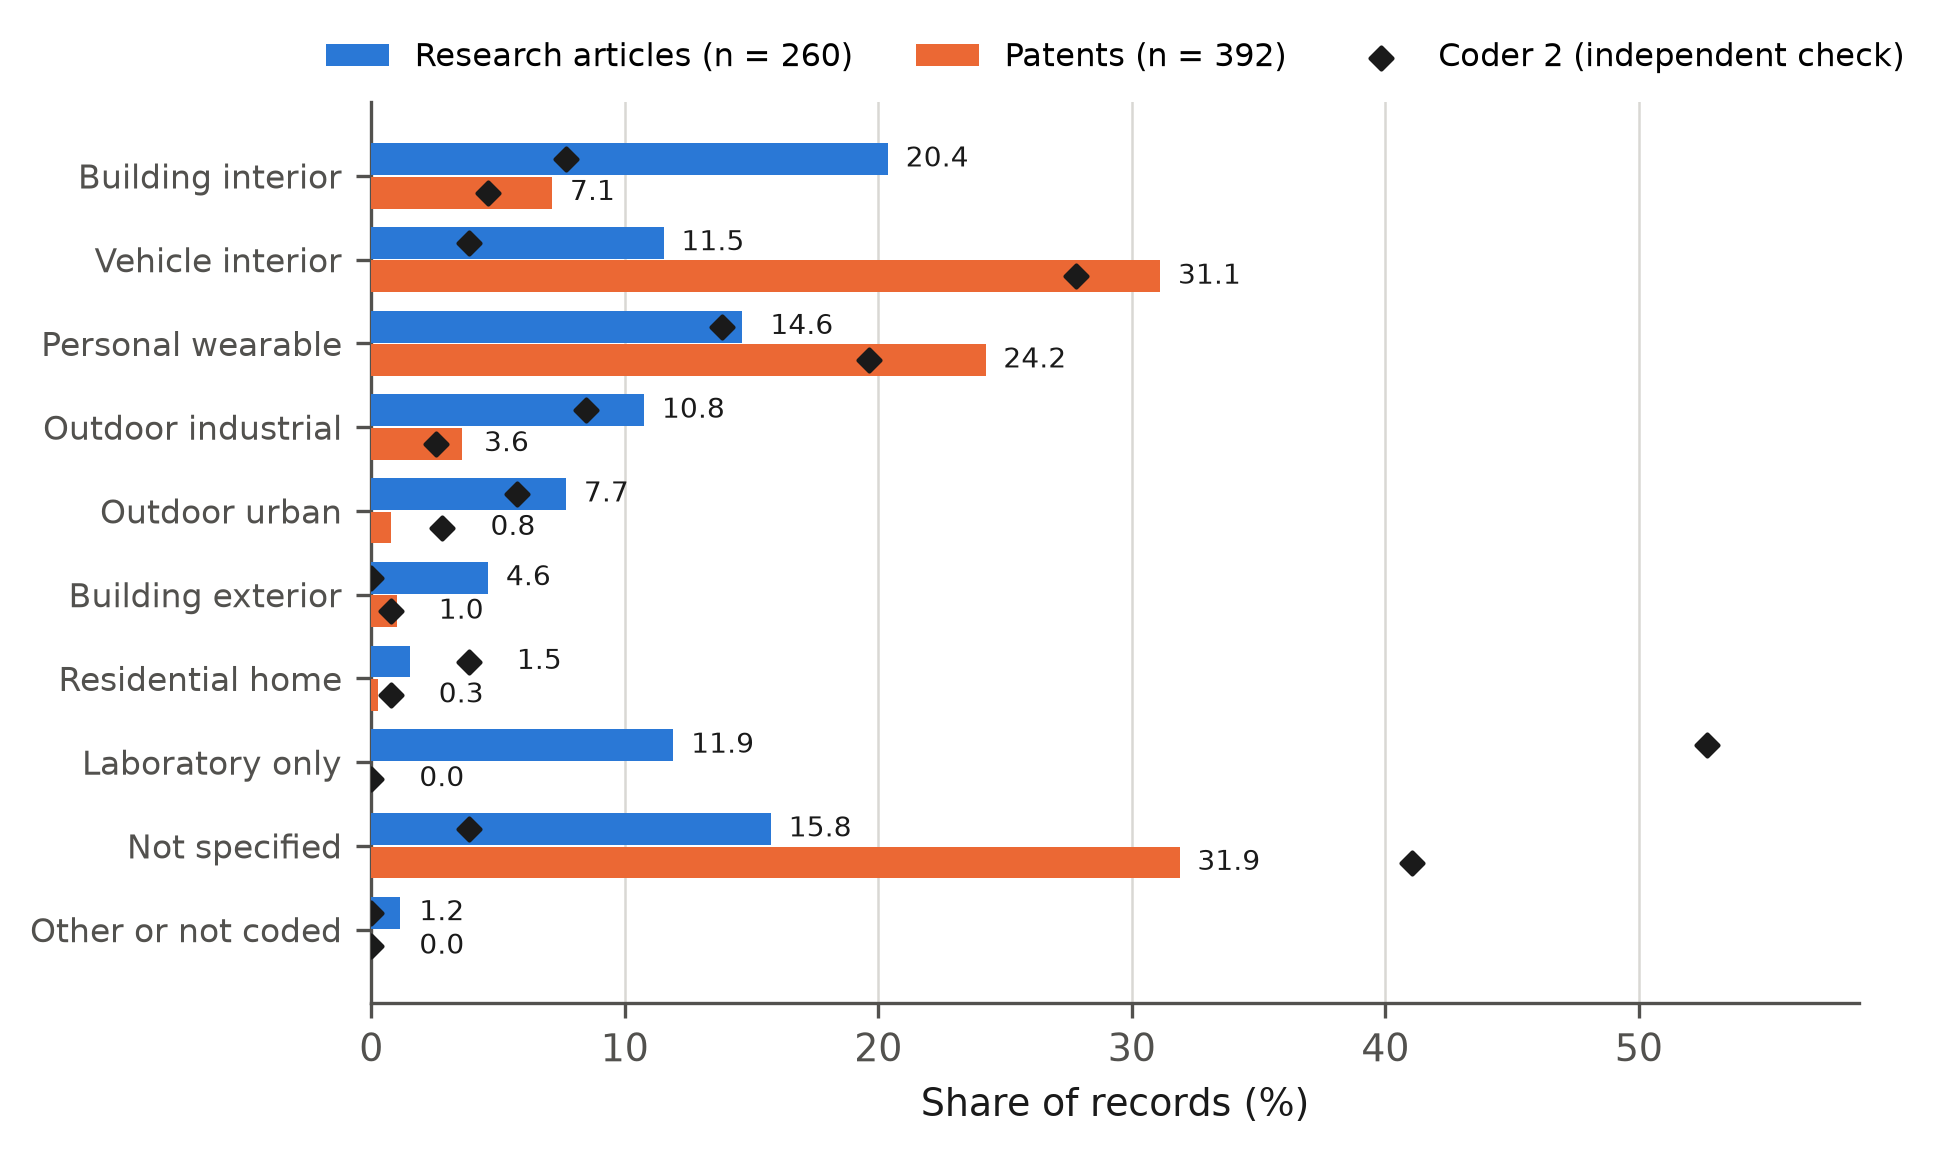

In [10]:
SET_ORDER = ["building_interior", "vehicle_interior", "personal_wearable", "outdoor_industrial", "outdoor_urban",
             "building_exterior", "residential_home", "laboratory_only", "not_specified", "other"]
SET_LAB = {"building_interior": "Building interior", "vehicle_interior": "Vehicle interior",
           "personal_wearable": "Personal wearable", "outdoor_industrial": "Outdoor industrial",
           "outdoor_urban": "Outdoor urban", "building_exterior": "Building exterior",
           "residential_home": "Residential home", "laboratory_only": "Laboratory only",
           "not_specified": "Not specified", "other": "Other or not coded"}
sa1 = A1.deployment_setting.replace({"not_coded": "other"}).value_counts(); sa2 = A2.deployment_setting.value_counts()
sp1 = P1.deployment_setting.value_counts(); sp2 = P2.deployment_setting.value_counts()
tab_set = pd.DataFrame({"Setting": [SET_LAB[s] for s in SET_ORDER],
                        "Articles, coder 1": [int(sa1.get(s, 0)) for s in SET_ORDER],
                        "Articles, coder 2": [int(sa2.get(s, 0)) for s in SET_ORDER],
                        "Patents, coder 1": [int(sp1.get(s, 0)) for s in SET_ORDER],
                        "Patents, coder 2": [int(sp2.get(s, 0)) for s in SET_ORDER]})
assert tab_set.iloc[:, 1:].sum().tolist() == [N_ART, N_ART, N_PAT, N_PAT]
tab_set.to_csv(TAB / "tableB3_settings_both_coders.csv", index=False)
display(tab_set)
for tag, sc, n in [("A1", sa1, N_ART), ("A2", sa2, N_ART), ("P1", sp1, N_PAT), ("P2", sp2, N_PAT)]:
    for s in SET_ORDER:
        PV[f"{tag}_SET_{s.upper()}_N"] = int(sc.get(s, 0)); PV[f"{tag}_SET_{s.upper()}_PCT"] = round(pct(sc.get(s, 0), n), 1)

fig, ax = plt.subplots(figsize=(6.4, 3.9))
y = np.arange(len(SET_ORDER))[::-1]; h = 0.38
va1 = np.array([pct(sa1.get(s, 0), N_ART) for s in SET_ORDER]); vp1 = np.array([pct(sp1.get(s, 0), N_PAT) for s in SET_ORDER])
va2 = np.array([pct(sa2.get(s, 0), N_ART) for s in SET_ORDER]); vp2 = np.array([pct(sp2.get(s, 0), N_PAT) for s in SET_ORDER])
ha_ = ax.barh(y + h / 2 + 0.01, va1, h, color=BLUE, label=f"Research articles (n = {N_ART})", zorder=3)
hp_ = ax.barh(y - h / 2 - 0.01, vp1, h, color=ORANGE, label=f"Patents (n = {N_PAT})", zorder=3)
d2 = ax.scatter(va2, y + h / 2 + 0.01, marker="D", s=14, color=INK, zorder=4, label="Coder 2 (independent check)")
ax.scatter(vp2, y - h / 2 - 0.01, marker="D", s=14, color=INK, zorder=4)
for bars, vals, v2s in [(ha_, va1, va2), (hp_, vp1, vp2)]:
    for r, v, v2 in zip(bars, vals, v2s):
        xx = max(v, v2 + 1.2) if 0 <= v2 - v < 3.5 or abs(v2 - v) < 1.2 else v
        ax.text(xx + 0.7, r.get_y() + r.get_height() / 2, f"{v:.1f}", va="center", fontsize=6.8, color=INK)
ax.set_yticks(y); ax.set_yticklabels([SET_LAB[s] for s in SET_ORDER], fontsize=8)
ax.set_xlabel("Share of records (%)"); ax.set_xlim(0, max(va1.max(), vp1.max(), va2.max(), vp2.max()) + 6)
ax.xaxis.grid(True, color=GRID, lw=0.6, zorder=0)
ax.legend(handles=[ha_, hp_, d2], frameon=False, fontsize=7.6, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3)
save(fig, "figure4_settings.png")

### 2.6 Capabilities by setting (Figure 5)

Counts of systems in each named setting that use AI together with a network link, that classify speech, or that sense continuously (coder 1).

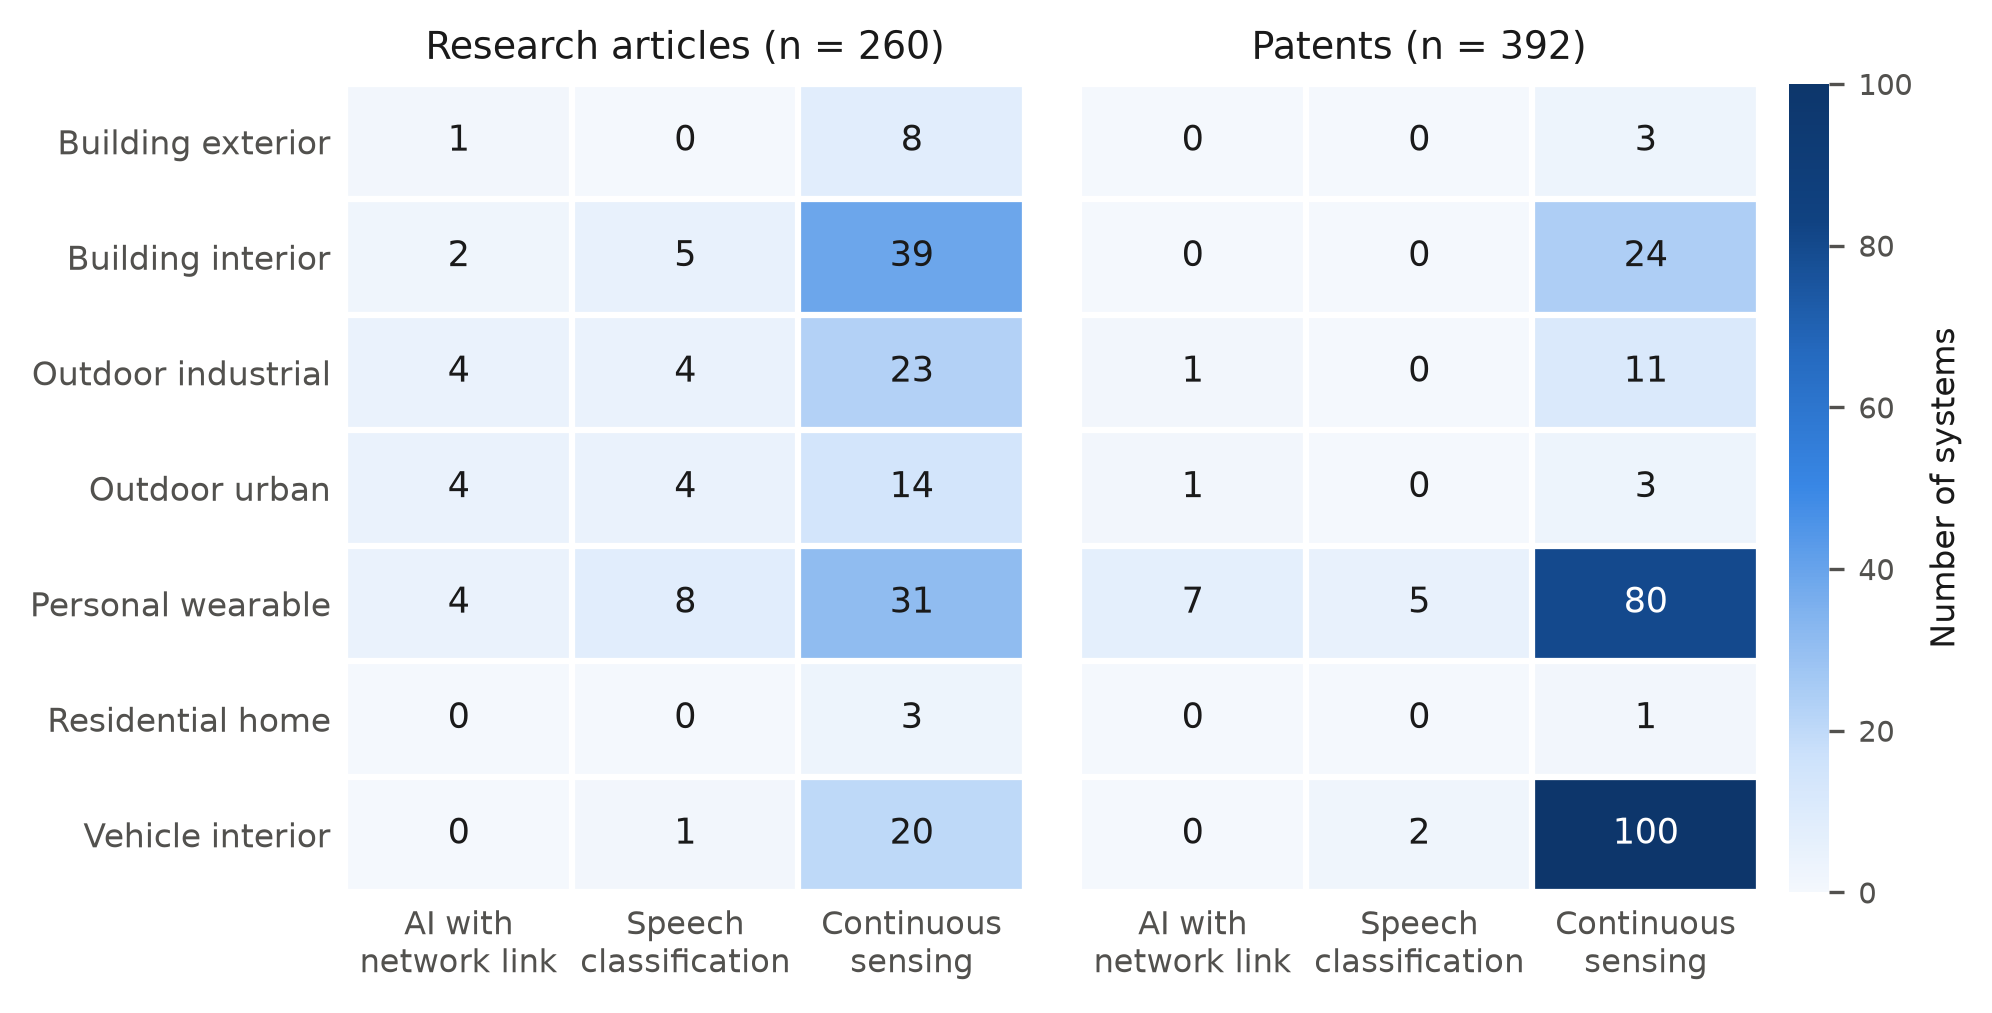

                    ai_net  speech  continuous
building_exterior        1       0           8
building_interior        2       5          39
outdoor_industrial       4       4          23
outdoor_urban            4       4          14
personal_wearable        4       8          31
residential_home         0       0           3
vehicle_interior         0       1          20
                    ai_net  speech  continuous
building_exterior        0       0           3
building_interior        0       0          24
outdoor_industrial       1       0          11
outdoor_urban            1       0           3
personal_wearable        7       5          80
residential_home         0       0           1
vehicle_interior         0       2         100


In [11]:
ROWS5 = ["building_exterior", "building_interior", "outdoor_industrial", "outdoor_urban", "personal_wearable",
         "residential_home", "vehicle_interior"]
COLS5 = ["AI with\nnetwork link", "Speech\nclassification", "Continuous\nsensing"]


def heat(d, I):
    H = np.zeros((len(ROWS5), 3), int)
    for i, s in enumerate(ROWS5):
        msk = (d.deployment_setting == s).values
        H[i, 0] = int((I.ai.values & I.network.values & msk).sum())
        H[i, 1] = int((I.speech_cls.values & msk).sum())
        H[i, 2] = int((I.continuous.values & msk).sum())
    return H


HA = heat(A1, IA1)
HP = heat(P1, IP1)
cmap = LinearSegmentedColormap.from_list("blue", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#104281", "#0d366b"])
fig, axes = plt.subplots(1, 2, figsize=(6.4, 3.5), gridspec_kw=dict(wspace=0.08))
vmax = max(HA.max(), HP.max())
for k, (ax, H, title) in enumerate(zip(axes, [HA, HP], [f"Research articles (n = {N_ART})", f"Patents (n = {N_PAT})"])):
    im = ax.imshow(H, cmap=cmap, vmin=0, vmax=vmax, aspect="auto")
    for i in range(H.shape[0]):
        for j in range(H.shape[1]):
            v = H[i, j]
            t = str(v)
            ax.text(j, i, t, ha="center", va="center", fontsize=8.3, color="white" if v > vmax * 0.45 else INK)
    ax.set_xticks(range(3)); ax.set_xticklabels(COLS5, fontsize=7.6)
    ax.set_yticks(range(len(ROWS5))); ax.set_yticklabels([SET_LAB[s] for s in ROWS5] if k == 0 else [], fontsize=8)
    ax.set_title(title, fontsize=9, color=INK); ax.tick_params(length=0)
    for sp_ in ax.spines.values():
        sp_.set_visible(False)
    ax.set_xticks(np.arange(-.5, 3, 1), minor=True); ax.set_yticks(np.arange(-.5, len(ROWS5), 1), minor=True)
    ax.grid(which="minor", color="white", lw=1.5); ax.tick_params(which="minor", length=0)
cb = fig.colorbar(im, ax=axes, fraction=0.03, pad=0.02)
cb.set_label("Number of systems", fontsize=8); cb.outline.set_visible(False); cb.ax.tick_params(labelsize=7)
save(fig, "figure5_heatmap.png")
for i, s in enumerate(ROWS5):
    for j, c in enumerate(["AINET", "SPEECH", "CONT"]):
        PV[f"H_A_{s.upper()}_{c}"] = int(HA[i, j]); PV[f"H_P_{s.upper()}_{c}"] = int(HP[i, j])
PV["A1_SPEECH_NAMED_SETTING"] = int(HA[:, 1].sum())
print(pd.DataFrame(HA, index=ROWS5, columns=["ai_net", "speech", "continuous"]))
print(pd.DataFrame(HP, index=ROWS5, columns=["ai_net", "speech", "continuous"]))

## Part 3. Inter-coder reliability (Table B1)

Reliability is computed on the **main round**: every record except the 15 articles and 15 patents of the pilot round, which coders used to calibrate the codebook (version 1 to version 2). The one article that coder 1 could not open (RA33) is also left out, because it has no code to compare. Speech classification of patents is not compared, because coder 1 coded it after the main round. For each binary indicator the cell reports percent agreement, Cohen's kappa with a 95% bootstrap confidence interval (2,000 resamples, seed 2026), and Gwet's AC1. AC1 is reported because kappa falls sharply when one category is very common or very rare (the kappa paradox), even when agreement is high. Coder 2's notes for every disagreement are written to `tables/disagreement_log.csv`.

In [12]:
def kappa(a, b):
    a, b = np.asarray(a), np.asarray(b)
    po = (a == b).mean()
    pe = sum((a == c).mean() * (b == c).mean() for c in np.union1d(a, b))
    return np.nan if pe == 1 else (po - pe) / (1 - pe)


def ac1(a, b):
    a, b = np.asarray(a), np.asarray(b)
    cats = np.union1d(a, b); q = len(cats)
    if q < 2:
        return 1.0
    po = (a == b).mean()
    pi = np.array([((a == c).mean() + (b == c).mean()) / 2 for c in cats])
    pe = (pi * (1 - pi)).sum() / (q - 1)
    return (po - pe) / (1 - pe)


def boot_ci(a, b, reps=2000, seed=2026):
    rng = np.random.default_rng(seed)
    a, b = np.asarray(a), np.asarray(b); n = len(a)
    vals = [kappa(a[i], b[i]) for i in (rng.integers(0, n, n) for _ in range(reps))]
    return np.nanpercentile(vals, [2.5, 97.5])


REL_VARS = ["continuous", "ai", "network", "sound_cls", "speech_cls", "cloud", "freq", "setting"]
REL_LAB = dict(LABELS, setting="Deployment setting (9 categories)")
rel_rows, dis_rows = [], []
for kind, D1, D2, I1, I2 in [("articles", A1, A2, IA1, IA2), ("patents", P1, P2, IP1, IP2)]:
    coded = (D1.continuous_sensing != "not_coded").values   # records that coder 1 could code
    for scope in ("main", "all"):
        msk = ((D2["round"] == "main").values if scope == "main" else np.ones(len(D2), bool)) & coded
        for v in REL_VARS:
            if kind == "patents" and v == "speech_cls":
                continue
            if v == "setting":
                a, b = D1.deployment_setting.values[msk], D2.deployment_setting.values[msk]
            else:
                a = np.where(I1[v].values[msk], "yes", "no"); b = np.where(I2[v].values[msk], "yes", "no")
            lo, hi = boot_ci(a, b)
            rel_rows.append(dict(corpus=kind, scope=scope, variable=REL_LAB[v], n=int(msk.sum()),
                                 agreement=(a == b).mean(), kappa=kappa(a, b), kappa_lo=lo, kappa_hi=hi, ac1=ac1(a, b),
                                 prevalence_c1=(a == "yes").mean() if v != "setting" else np.nan,
                                 prevalence_c2=(b == "yes").mean() if v != "setting" else np.nan))
            if scope == "all":
                col = "deployment_setting" if v == "setting" else FEAT[v][0]
                rows_ = np.where(msk)[0]
                for i in rows_[a != b]:
                    dis_rows.append(dict(corpus=kind, round=D2["round"].values[i], id=D1.id.values[i], variable=REL_LAB[v],
                                         coder1_code=D1[col].values[i], coder2_code=D2[col].values[i],
                                         coder2_note=D2.note.values[i], adjudication=""))
REL = pd.DataFrame(rel_rows)
REL.to_csv(TAB / "reliability_full.csv", index=False, float_format="%.4f")
DIS = pd.DataFrame(dis_rows)
DIS.to_csv(TAB / "disagreement_log.csv", index=False)
main = REL[REL.scope == "main"].copy()
tabB1 = pd.DataFrame({"Variable": [REL_LAB[v] for v in REL_VARS]})
for kind, lab in [("articles", "Articles"), ("patents", "Patents")]:
    s = main[main.corpus == kind].set_index("variable")
    tabB1[f"{lab}: agreement (%)"] = [f"{100 * s.loc[REL_LAB[v], 'agreement']:.1f}" if REL_LAB[v] in s.index else "not compared" for v in REL_VARS]
    tabB1[f"{lab}: kappa [95% CI]"] = [f"{s.loc[REL_LAB[v], 'kappa']:.2f} [{s.loc[REL_LAB[v], 'kappa_lo']:.2f}, {s.loc[REL_LAB[v], 'kappa_hi']:.2f}]"
                                       if REL_LAB[v] in s.index else "not compared" for v in REL_VARS]
    tabB1[f"{lab}: AC1"] = [f"{s.loc[REL_LAB[v], 'ac1']:.2f}" if REL_LAB[v] in s.index else "not compared" for v in REL_VARS]
tabB1 = tabB1.replace("-", "−", regex=True)
tabB1.to_csv(TAB / "tableB1_reliability.csv", index=False)
nA = int(main[main.corpus == "articles"].n.iloc[0]); nP = int(main[main.corpus == "patents"].n.iloc[0])
print(f"Main round: {nA} articles and {nP} patents")
display(tabB1)
for r in main.itertuples():
    key = [k for k, v in REL_LAB.items() if v == r.variable][0].upper()
    tag = "RA" if r.corpus == "articles" else "RP"
    PV[f"{tag}_{key}_AGR"] = round(100 * r.agreement, 1); PV[f"{tag}_{key}_K"] = round(r.kappa, 2)
    PV[f"{tag}_{key}_KLO"] = round(r.kappa_lo, 2); PV[f"{tag}_{key}_KHI"] = round(r.kappa_hi, 2); PV[f"{tag}_{key}_AC1"] = round(r.ac1, 2)
PV["REL_N_ART"], PV["REL_N_PAT"], PV["N_DISAGREE"] = nA, nP, len(DIS)
print("Disagreements written:", len(DIS))
print(DIS.groupby(["corpus", "variable"]).size().to_string())

Main round: 244 articles and 377 patents


,Variable,Articles: agreement (%),Articles: kappa [95% CI],Articles: AC1,Patents: agreement (%),Patents: kappa [95% CI],Patents: AC1
0,Continuous sensing,70.1,"0.21 [0.08, 0.33]",0.53,79.8,"0.20 [0.08, 0.32]",0.73
1,AI or ML,92.6,"0.83 [0.75, 0.90]",0.87,95.5,"0.76 [0.64, 0.86]",0.94
2,Network connectivity,91.0,"0.71 [0.59, 0.82]",0.87,94.4,"0.63 [0.45, 0.75]",0.93
3,Sound classification,87.3,"0.50 [0.33, 0.65]",0.83,92.0,"0.64 [0.51, 0.75]",0.90
4,Speech classification,92.2,"0.45 [0.22, 0.64]",0.91,not compared,not compared,not compared
5,Cloud or hybrid processing,97.5,"0.56 [0.13, 0.85]",0.97,97.9,"0.42 [0.00, 0.71]",0.98
6,Frequency domain processing,91.0,"0.79 [0.70, 0.86]",0.84,55.4,"0.01 [−0.06, 0.06]",0.28
7,Deployment setting (9 categories),44.7,"0.37 [0.30, 0.44]",0.39,84.6,"0.79 [0.74, 0.84]",0.83


Disagreements written: 734
corpus    variable                         
articles  AI or ML                              20
          Cloud or hybrid processing             7
          Continuous sensing                    76
          Deployment setting (9 categories)    141
          Frequency domain processing           22
          Network connectivity                  23
          Sound classification                  34
          Speech classification                 20
patents   AI or ML                              17
          Cloud or hybrid processing             8
          Continuous sensing                    79
          Deployment setting (9 categories)     60
          Frequency domain processing          175
          Network connectivity                  22
          Sound classification                  30


**Where the coders differ.** The cross tabulations below show that most disagreements are threshold differences, not random errors. Coder 1 often coded continuous sensing as unclear when a text did not say so in words, while coder 2 coded every microphone-based controller as continuous (codebook v2, rule 5). For patent processing domain, coder 1 coded frequency domain whenever an abstract mentioned frequency bands, while coder 2 required a spectral algorithm and otherwise coded unclear (rule 1). For article settings, coder 2 coded laboratory_only whenever a study was tested only in a laboratory and named an application only in passing.

In [13]:
for kind, D1, D2 in [("articles", A1, A2), ("patents", P1, P2)]:
    msk = (D2["round"] == "main").values & (D1.continuous_sensing != "not_coded").values
    for c in ["continuous_sensing", "processing_domain"]:
        print(f"\n{kind}: {c} (rows coder 1, columns coder 2), main round")
        print(pd.crosstab(D1[c].values[msk], D2[c].values[msk]).to_string())


articles: continuous_sensing (rows coder 1, columns coder 2), main round
col_0    no  unclear  yes
row_0                    
no        1        2    0
unclear   0       18   60
yes       4        9  150

articles: processing_domain (rows coder 1, columns coder 2), main round
col_0             frequency_domain  time_domain  time_frequency  unclear
row_0                                                                   
frequency_domain                24            3               4        3
time_domain                      4          145               4        7
time_frequency                   8            0              27        7
unclear                          0            2               1        5

patents: continuous_sensing (rows coder 1, columns coder 2), main round
col_0    no  unclear  yes
row_0                    
unclear   0       16   58
yes       7       11  285

patents: processing_domain (rows coder 1, columns coder 2), main round
col_0             frequency_domain  

**Pilot round.** The pilot items were first coded blind with codebook version 1 and compared with coder 1. The table shows agreement on the binary indicators before calibration (v1) and after the pilot items were recoded with version 2 (not blind, so not used for reliability).

In [14]:
pil_rows = []
for kind, D1, I1 in [("articles", A1, IA1), ("patents", P1, IP1)]:
    v1 = pd.read_csv(CORPUS / f"coder2_pilot_v1_{kind}.csv", dtype=str); v1["id"] = v1.id.str.strip()
    for c in v1.columns:
        if c not in ("id", "note"):
            v1[c] = _s(v1[c])
    v1 = v1.set_index("id")
    ids = [i for i in D1.id if i in v1.index]
    Iv1 = indicators(v1.loc[ids].reset_index())
    I2p = (IA2 if kind == "articles" else IP2).loc[ids]
    for v in [x for x in REL_VARS if x != "setting"]:
        if kind == "patents" and v == "speech_cls":
            continue
        a = I1.loc[ids, v].values
        pil_rows.append(dict(corpus=kind, variable=LABELS[v], n=len(ids),
                             agreement_v1=(a == Iv1[v].values).mean(), agreement_v2=(a == I2p[v].values).mean()))
display(pd.DataFrame(pil_rows).round(2))

,corpus,variable,n,agreement_v1,agreement_v2
0,articles,Continuous sensing,15,0.80,0.80
1,articles,AI or ML,15,0.87,0.87
2,articles,Network connectivity,15,0.93,0.93
3,articles,Sound classification,15,0.80,0.80
4,articles,Speech classification,15,0.93,0.93
5,articles,Cloud or hybrid processing,15,0.93,0.93
6,articles,Frequency domain processing,15,1.00,1.00
7,patents,Continuous sensing,15,0.73,0.80
8,patents,AI or ML,15,1.00,1.00
9,patents,Network connectivity,15,0.93,0.93


## Part 4. Experiments A, B, and C (Figures 7 to 9, Tables 6 and 7)

### 4.1 Audio data

The two datasets are downloaded at the commits used for the paper. Only the `clean_test` folder of MS-SNSD is needed. The manifest lists every audio file the experiments read, with its SHA-256 checksum.

In [15]:
ESC_DIR = EXTERNAL / "ESC-50"
MSSNSD_DIR = EXTERNAL / "MS-SNSD"


def git(*args, cwd=None):
    subprocess.run(["git", *args], check=True, cwd=cwd, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)


def fetch_datasets():
    if not (ESC_DIR / "meta" / "esc50.csv").exists():
        git("clone", "--filter=blob:none", "--no-checkout", "https://github.com/karolpiczak/ESC-50.git", str(ESC_DIR))
        git("checkout", ESC50_COMMIT, cwd=ESC_DIR)
    if not (MSSNSD_DIR / "clean_test").exists():
        git("clone", "--filter=blob:none", "--no-checkout", "--sparse", "https://github.com/microsoft/MS-SNSD.git", str(MSSNSD_DIR))
        git("sparse-checkout", "set", "clean_test", cwd=MSSNSD_DIR)
        git("checkout", MSSNSD_COMMIT, cwd=MSSNSD_DIR)


if RECOMPUTE_EXPERIMENTS:
    fetch_datasets()
    print("ESC-50 files:", len(glob.glob(str(ESC_DIR / "audio" / "*.wav"))),
          " MS-SNSD clean_test files:", len(glob.glob(str(MSSNSD_DIR / "clean_test" / "*.wav"))))

ESC-50 files: 2000  MS-SNSD clean_test files: 1100


### 4.2 Shared signal processing

All audio is resampled to 16 kHz mono. Third octave bands follow the base ten definition of IEC 61260-1 (22 bands, nominal 50 Hz to 6.3 kHz). A-weighting follows IEC 61672-1. Band energies come from a fine short time Fourier transform (2,048 points, 128 sample hop) and are then averaged over an integration time T. Levels are in dB relative to digital full scale because the datasets carry no acoustic calibration.

In [16]:
import librosa
import soundfile as sf
from pystoi import stoi as _pystoi


def stoi(x, y, fs, extended=False):
    """STOI or ESTOI from pystoi with a fixed random state.

    pystoi's ESTOI adds tiny random noise from NumPy's global generator before it normalizes each
    segment. For segments with almost no energy this noise decides the result, so the generator is
    fixed before every call. Each score is then the same in every run and in every worker process."""
    np.random.seed(0)
    return _pystoi(x, y, fs, extended=extended)
from scipy import stats
from multiprocessing import get_context
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.exceptions import ConvergenceWarning
warnings.simplefilter("error", ConvergenceWarning)  # a solver that stops early would make results machine dependent
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

FS = 16000
N_FFT, HOP = 2048, 128
FREQS = librosa.fft_frequencies(sr=FS, n_fft=N_FFT)
CENTERS = 1000.0 * 10 ** (np.arange(-13, 9) / 10.0)
LOWER, UPPER = CENTERS * 10 ** (-0.05), CENTERS * 10 ** 0.05
N_BANDS = len(CENTERS)
BAND_IDX = [np.where((FREQS >= lo) & (FREQS < hi))[0] for lo, hi in zip(LOWER, UPPER)]
A_W = librosa.A_weighting(FREQS)
A_W_BAND = librosa.A_weighting(CENTERS)
EPS = 1e-12
URBAN = ["siren", "car_horn", "engine", "train", "helicopter", "airplane", "chainsaw", "hand_saw", "fireworks", "church_bells"]


def load(path, sr=FS):
    y, s = sf.read(path, dtype="float32", always_2d=False)
    if y.ndim > 1:
        y = y.mean(axis=1)
    if s != sr:
        y = librosa.resample(y, orig_sr=s, target_sr=sr)
    return y.astype(np.float32)


def stft(y):
    return librosa.stft(y, n_fft=N_FFT, hop_length=HOP, window="hann", center=True)


def istft(S, length):
    return librosa.istft(S, hop_length=HOP, window="hann", center=True, length=length)


def power_spec(y):
    return np.abs(stft(y)) ** 2


def third_octave(P, frame_s):
    k = max(1, int(round(frame_s / (HOP / FS))))
    nT = P.shape[1] // k
    B = np.stack([P[:, : nT * k][idx].sum(axis=0) for idx in BAND_IDX])
    return B.reshape(N_BANDS, nT, k).mean(axis=2), k


def laeq_from_wave(y):
    P = power_spec(y)
    return 10 * np.log10((P * (10 ** (A_W / 10.0))[:, None]).sum() / P.shape[1] + EPS)


def bands_to_spec(B, k, n_frames):
    M = np.zeros((len(FREQS), B.shape[1]), dtype=np.float32)
    for b, idx in enumerate(BAND_IDX):
        if len(idx):
            M[idx] = B[b] / len(idx)
    M = np.repeat(M, k, axis=1)
    if M.shape[1] < n_frames:
        M = np.pad(M, ((0, 0), (0, n_frames - M.shape[1])), mode="edge")
    return np.sqrt(np.maximum(M[:, :n_frames], 0))


def griffin_lim(mag, length, n_iter=100, seed=0):
    return librosa.griffinlim(mag, n_iter=n_iter, hop_length=HOP, window="hann", n_fft=N_FFT, length=length,
                              rng=np.random.default_rng(seed)).astype(np.float32)


# file selections (fixed seeds), shared by the three experiments
if RECOMPUTE_EXPERIMENTS:
    SPEECH_FILES = sorted(glob.glob(str(MSSNSD_DIR / "clean_test" / "*.wav")))
    ESC_META = pd.read_csv(ESC_DIR / "meta" / "esc50.csv")
else:
    SPEECH_FILES = json.load(open(EXPDIR / "manifest.json"))["speech_files_sorted"]
    ESC_META = None
SEL_A = sorted(np.random.default_rng(2026).choice(len(SPEECH_FILES), size=100, replace=False).tolist())
_pool_b = [i for i in range(len(SPEECH_FILES)) if i not in set(SEL_A)]
SEL_B = np.random.default_rng(7).choice(_pool_b, size=40, replace=False)
_used = set(SEL_A) | set(SEL_B.tolist())
POOL_C = [i for i in range(len(SPEECH_FILES)) if i not in _used]
np.random.default_rng(11).shuffle(POOL_C)
print("speech files:", len(SPEECH_FILES), " Exp A:", len(SEL_A), " Exp B speech:", len(SEL_B), " Exp C pool:", len(POOL_C))

speech files: 1100  Exp A: 100  Exp B speech: 40  Exp C pool: 960


In [17]:
# ---- Verify the audio inputs against the manifest ---------------------------
def sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


MANIFEST = json.load(open(EXPDIR / "manifest.json"))
if RECOMPUTE_EXPERIMENTS:
    assert [Path(p).name for p in SPEECH_FILES] == MANIFEST["speech_files_sorted"], "speech file list differs"
    bad = [n for n, h in MANIFEST["sha256"].items()
           if sha256((MSSNSD_DIR / "clean_test" / n) if not n.startswith("esc/") else (ESC_DIR / "audio" / n[4:])) != h]
    print("Audio files checked:", len(MANIFEST["sha256"]), " mismatches:", len(bad))
    assert not bad, bad[:5]

Audio files checked: 900  mismatches: 0


### 4.3 Experiment A: what an attacker can rebuild from each sensor output

For 100 clean utterances (first 8 s), the sensor output is formed under each design and an attacker rebuilds audio with 100 iterations of fast Griffin-Lim. Intelligibility is scored against the original with STOI and ESTOI. The floor is noise with the utterance's long term spectrum and no time detail.

In [18]:
FRAMES_A = [0.020, 0.050, 0.125, 0.250, 0.500, 1.000]


def run_a(i):
    x = load(SPEECH_FILES[i])[: 8 * FS]
    x = x / (np.max(np.abs(x)) + 1e-9) * 0.5
    L = len(x)
    sc = lambda y: (float(stoi(x, y, FS, extended=False)), float(stoi(x, y, FS, extended=True)))
    out = {"file": Path(SPEECH_FILES[i]).name, "dur_s": L / FS}
    S = stft(x); P = np.abs(S) ** 2; nF = S.shape[1]
    out["R1_fine_mag"] = sc(griffin_lim(np.abs(S), L, seed=i))
    M = librosa.feature.melspectrogram(y=x, sr=FS, n_fft=1024, hop_length=512, n_mels=64, power=2.0)
    Smel = librosa.feature.inverse.mel_to_stft(M, sr=FS, n_fft=1024, power=2.0)      # same steps as mel_to_audio,
    out["R2_mel64_32ms"] = sc(librosa.griffinlim(Smel, n_iter=100, hop_length=512, n_fft=1024, window="hann", center=True,
                                                 dtype=np.float32, length=L, pad_mode="constant",
                                                 rng=np.random.default_rng(i)))           # with a fixed seed
    for f in FRAMES_A:
        B, k = third_octave(P, f)
        out[f"R3_tob_{int(f * 1000)}ms"] = sc(griffin_lim(bands_to_spec(B, k, nF), L, seed=i))
    ltas = np.sqrt(P.mean(axis=1, keepdims=True))
    ph = np.exp(2j * np.pi * np.random.default_rng(1000 + i).random(S.shape))
    out["floor_ltas_noise"] = sc(istft(ltas * ph, L))
    return out


if RECOMPUTE_EXPERIMENTS:
    with get_context("fork").Pool(N_JOBS) as pool:
        RA_ = []
        for n, r in enumerate(pool.imap(run_a, SEL_A)):
            RA_.append(r)
            if n % 10 == 9:
                print(f"  Experiment A: {n + 1}/100", flush=True)
    json.dump(RA_, open(RES / "results_a.json", "w"), indent=1)
else:
    RA_ = json.load(open(EXPDIR / "results_a.json"))
print("Experiment A records:", len(RA_))

  Experiment A: 10/100


  Experiment A: 20/100


  Experiment A: 30/100


  Experiment A: 40/100


  Experiment A: 50/100


  Experiment A: 60/100


  Experiment A: 70/100


  Experiment A: 80/100


  Experiment A: 90/100


  Experiment A: 100/100


Experiment A records: 100


### 4.4 Experiment B: is the coarse output still useful?

Ten urban classes of ESC-50 (40 clips each) and a speech class (40 utterances not used in Experiment A) are summarized by five statistics per band. Two small classifiers are trained with five fold cross validation on the official ESC-50 folds.

In [19]:
def stats5(Ldb, active):
    Lm = Ldb[:, active] if active.sum() >= 2 else Ldb
    d = np.abs(np.diff(Lm, axis=1)).mean(axis=1) if Lm.shape[1] > 1 else np.zeros(Lm.shape[0])
    return np.concatenate([Lm.mean(1), Lm.std(1), np.percentile(Lm, 10, 1), np.percentile(Lm, 90, 1), d])


def feats_b(path):
    x = load(path)[: 5 * FS]
    x = np.pad(x, (0, max(0, 5 * FS - len(x))))
    P = power_spec(x)
    out = {}
    for name, f in [("tob_125ms", 0.125), ("tob_1s", 1.0)]:
        B, k = third_octave(P, f)
        Ldb = 10 * np.log10(B + EPS); tot = 10 * np.log10(B.sum(0) + EPS)
        active = tot > tot.max() - 50
        out[name] = np.concatenate([stats5(Ldb, active), stats5(tot[None, :], active)])
    B, k = third_octave(P, 0.125)
    la = 10 * np.log10((B * 10 ** (A_W_BAND[:, None] / 10)).sum(0) + EPS)
    out["laeq_only"] = stats5(la[None, :], la > la.max() - 50)
    M = librosa.feature.melspectrogram(y=x, sr=FS, n_fft=1024, hop_length=512, n_mels=64)
    Ldb = 10 * np.log10(M + EPS); tot = 10 * np.log10(M.sum(0) + EPS)
    out["mel64_32ms"] = stats5(Ldb, tot > tot.max() - 50)
    return out


CLASSES_B = URBAN + ["speech"]
if RECOMPUTE_EXPERIMENTS:
    mb = ESC_META[ESC_META.category.isin(URBAN)].reset_index(drop=True)
    clips = [(str(ESC_DIR / "audio" / r.filename), r.category, int(r.fold)) for r in mb.itertuples()]
    clips += [(SPEECH_FILES[i], "speech", n % 5 + 1) for n, i in enumerate(SEL_B)]
    with get_context("fork").Pool(N_JOBS) as pool:
        F = pool.map(feats_b, [c[0] for c in clips])
    yb = np.array([CLASSES_B.index(c[1]) for c in clips]); folds = np.array([c[2] for c in clips])
    RB_ = {}
    for rep in ["laeq_only", "tob_1s", "tob_125ms", "mel64_32ms"]:
        X = np.stack([f[rep] for f in F])
        for mname, mk in [("logreg", lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.5, solver="newton-cholesky", tol=1e-8, max_iter=1000))),
                          ("rf", lambda: RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=1))]:
            accs, yt, yp = [], [], []
            for k in range(1, 6):
                tr, te = folds != k, folds == k
                pr = mk().fit(X[tr], yb[tr]).predict(X[te])
                accs.append(float((pr == yb[te]).mean())); yt += yb[te].tolist(); yp += pr.tolist()
            yt, yp = np.array(yt), np.array(yp); sp_ = CLASSES_B.index("speech")
            p_, r_, _, _ = precision_recall_fscore_support(yt == sp_, yp == sp_, average="binary")
            _, rec, _, _ = precision_recall_fscore_support(yt, yp, labels=range(len(CLASSES_B)), zero_division=0)
            RB_[f"{rep}|{mname}"] = dict(acc_mean=float(np.mean(accs)), acc_sd=float(np.std(accs, ddof=1)), fold_acc=accs,
                                         speech_precision=float(p_), speech_recall=float(r_),
                                         per_class_recall=dict(zip(CLASSES_B, map(float, rec))), n_features=int(X.shape[1]),
                                         n_params=(X.shape[1] + 1) * len(CLASSES_B) if mname == "logreg" else None,
                                         confusion=confusion_matrix(yt, yp).tolist())
    RB_["classes"] = CLASSES_B
    json.dump(RB_, open(RES / "results_b.json", "w"), indent=1)
else:
    RB_ = json.load(open(EXPDIR / "results_b.json"))
for k, v in RB_.items():
    if k != "classes":
        print(f"{k:22s} accuracy {v['acc_mean']:.3f} (sd {v['acc_sd']:.3f})  speech P/R {v['speech_precision']:.2f}/{v['speech_recall']:.2f}")

laeq_only|logreg       accuracy 0.434 (sd 0.052)  speech P/R 0.59/0.80
laeq_only|rf           accuracy 0.452 (sd 0.026)  speech P/R 0.61/0.75
tob_1s|logreg          accuracy 0.611 (sd 0.048)  speech P/R 0.88/0.95
tob_1s|rf              accuracy 0.577 (sd 0.055)  speech P/R 0.87/0.97
tob_125ms|logreg       accuracy 0.711 (sd 0.077)  speech P/R 0.95/1.00
tob_125ms|rf           accuracy 0.682 (sd 0.053)  speech P/R 0.82/1.00
mel64_32ms|logreg      accuracy 0.730 (sd 0.042)  speech P/R 1.00/1.00
mel64_32ms|rf          accuracy 0.650 (sd 0.050)  speech P/R 0.89/1.00


### 4.5 Experiment C: fixed versus adaptive redaction

Each test mixture is a 5 s urban clip with 3 s of speech between 1.0 s and 4.0 s, at 0 dB or +10 dB speech to noise ratio. A frame level speech detector (logistic regression on third octave levels in 125 ms frames) is trained on ESC-50 folds 1 to 3 and tested on folds 4 and 5. Six redaction policies are compared.

In [20]:
FR = 0.125
K_C = int(round(FR / (HOP / FS)))
BAND_NARROW = (FREQS >= 500) & (FREQS <= 4000)
BAND_FULL = (FREQS >= 150) & (FREQS <= 5000)
SEG = (1 * FS, 4 * FS)


def speech_seg(i):
    x = load(SPEECH_FILES[i])
    x = np.pad(x, (0, max(0, 3 * FS - len(x))))
    c = np.concatenate([[0.0], np.cumsum(x.astype(np.float64) ** 2)])
    s0 = int(min(np.argmax(c[FS:] - c[:-FS]), len(x) - 3 * FS))
    return x[s0: s0 + 3 * FS]


def mixture(noise_path, sp, snr_db):
    n = load(noise_path)[: 5 * FS]
    n = np.pad(n, (0, max(0, 5 * FS - len(n))))
    n = n / (np.sqrt(np.mean(n ** 2)) + 1e-9) * 0.05
    s = np.zeros(5 * FS, np.float32); s[SEG[0]:SEG[1]] = sp
    s *= np.sqrt((np.mean(n[SEG[0]:SEG[1]] ** 2) + 1e-12) / (np.mean(sp ** 2) + 1e-12) * 10 ** (snr_db / 10))
    return n + s, s, n


def frame_feats(x):
    B, _ = third_octave(power_spec(x), FR)
    L = 10 * np.log10(B + EPS)
    D = L - np.percentile(L, 20, axis=1, keepdims=True)
    T = D.shape[1]
    Dp = np.pad(D, ((0, 0), (2, 2)), mode="edge")
    return np.concatenate([Dp[:, j:j + T] for j in range(5)], axis=0).T


def frame_labels(s):
    e = power_spec(s).sum(0)
    T = len(e) // K_C
    e = e[: T * K_C].reshape(T, K_C).mean(1)
    return e > (e.max() * 10 ** (-35 / 10))


def _fine(flags, n):
    f = np.repeat(flags, K_C)
    return np.pad(f, (0, max(0, n - len(f))), constant_values=False)[:n]


def apply_mask(x, flags, band=None):
    band = BAND_FULL if band is None else band
    S = stft(x)
    S[np.ix_(band, _fine(flags, S.shape[1]))] = 0
    return istft(S, len(x))


def apply_substitute(x, flags, block_s=1.0, seed=0):
    rng = np.random.default_rng(seed)
    S = stft(x); P = np.abs(S) ** 2
    Z = stft(rng.standard_normal(len(x)).astype(np.float32))
    f = _fine(flags, S.shape[1]); kb = int(round(block_s / (HOP / FS)))
    idx = np.where(f)[0]
    if len(idx) == 0:
        return x.copy()
    for run in np.split(idx, np.where(np.diff(idx) > 1)[0] + 1):
        for b0 in range(0, len(run), kb):
            blk = run[b0:b0 + kb]
            for bins in BAND_IDX:
                bins = bins[BAND_FULL[bins]]
                if len(bins):
                    ix = np.ix_(bins, blk)
                    S[ix] = np.sqrt(P[ix].sum() / (np.abs(Z[ix]) ** 2).sum()) * Z[ix]
    return istft(S, len(x))


def dilate(f):
    g = f.copy(); g[1:] |= f[:-1]; g[:-1] |= f[1:]
    return g


def levels(x):
    B, _ = third_octave(power_spec(x), 5.0)
    return laeq_from_wave(x), 10 * np.log10(B[:, 0] + EPS)


POLICIES = ["P0_none", "P1a_fixed_500_4k", "P1b_fixed_150_5k", "P2_adaptive_zero", "P3_adaptive_substitute", "P4_oracle_substitute"]


def run_c_one(args):
    j, fname, cls, det = args
    sp = speech_seg(POOL_C[200 + j]); rows = []
    for snr in (0, 10):
        mix, s, n = mixture(str(ESC_DIR / "audio" / fname), sp, snr)
        X = frame_feats(mix); lab = frame_labels(s)[: len(X)]
        pred = det.predict(X)[: len(lab)].astype(bool)
        on, det_f, ora_f = np.ones(len(lab), bool), dilate(pred), dilate(lab)
        out = {"P0_none": mix, "P1a_fixed_500_4k": apply_mask(mix, on, BAND_NARROW), "P1b_fixed_150_5k": apply_mask(mix, on),
               "P2_adaptive_zero": apply_mask(mix, det_f), "P3_adaptive_substitute": apply_substitute(mix, det_f, seed=j),
               "P4_oracle_substitute": apply_substitute(mix, ora_f, seed=j)}
        frac = {"P0_none": 0.0, "P1a_fixed_500_4k": 1.0, "P1b_fixed_150_5k": 1.0, "P2_adaptive_zero": det_f.mean(),
                "P3_adaptive_substitute": det_f.mean(), "P4_oracle_substitute": ora_f.mean()}
        ref_la, ref_b = levels(mix); seg = slice(*SEG); mid = (CENTERS >= 500) & (CENTERS <= 4000)
        row = dict(cls=cls, file=fname, snr=snr, det_tp=int((pred & lab).sum()), det_fp=int((pred & ~lab).sum()),
                   det_fn=int((~pred & lab).sum()), det_tn=int((~pred & ~lab).sum()),
                   floor_stoi=float(stoi(s[seg], n[seg], FS)), floor_estoi=float(stoi(s[seg], n[seg], FS, extended=True)))
        for name in POLICIES:
            y = out[name]; la, b = levels(y)
            row[name] = dict(stoi=float(stoi(s[seg], y[seg], FS)), estoi=float(stoi(s[seg], y[seg], FS, extended=True)),
                             dLAeq=float(la - ref_la), band_mae_500_4k=float(np.mean(np.abs(b[mid] - ref_b[mid]))),
                             frac_frames_redacted=float(frac[name]))
        rows.append(row)
    return rows


if RECOMPUTE_EXPERIMENTS:
    mc = ESC_META[ESC_META.category.isin(URBAN)].reset_index(drop=True)
    tr_c, te_c = mc[mc.fold <= 3], mc[mc.fold >= 4]
    Xs, ys, pi = [], [], 0
    for r in tr_c.itertuples():
        for snr in (0, 10):
            mix, s, n = mixture(str(ESC_DIR / "audio" / r.filename), speech_seg(POOL_C[pi % 200]), snr); pi += 1
            X = frame_feats(mix); lab = frame_labels(s)[: len(X)]
            Xs.append(X[: len(lab)]); ys.append(lab)
    Xtr, ytr = np.concatenate(Xs), np.concatenate(ys)
    DET = make_pipeline(StandardScaler(), LogisticRegression(C=0.5, solver="newton-cholesky", tol=1e-8, max_iter=1000, class_weight="balanced")).fit(Xtr, ytr)
    jobs = [(j, r.filename, r.category, DET) for j, r in enumerate(te_c.itertuples())]
    with get_context("fork").Pool(N_JOBS) as pool:
        rows_c = []
        for n, rr in enumerate(pool.imap(run_c_one, jobs)):
            rows_c += rr
            if n % 20 == 19:
                print(f"  Experiment C: {n + 1}/{len(jobs)} noise clips", flush=True)
    RC_ = dict(rows=rows_c, detector_params=int(Xtr.shape[1] + 1), n_train_frames=int(len(ytr)), train_speech_frac=float(ytr.mean()))
    json.dump(RC_, open(RES / "results_c.json", "w"), indent=1)
else:
    RC_ = json.load(open(EXPDIR / "results_c.json"))
print("Experiment C rows:", len(RC_["rows"]), " detector parameters:", RC_["detector_params"])

  Experiment C: 20/160 noise clips


  Experiment C: 40/160 noise clips


  Experiment C: 60/160 noise clips


  Experiment C: 80/160 noise clips


  Experiment C: 100/160 noise clips


  Experiment C: 120/160 noise clips


  Experiment C: 140/160 noise clips


  Experiment C: 160/160 noise clips


Experiment C rows: 320  detector parameters: 111


### 4.6 Statistics, Figures 7 to 9, and Tables 6 and 7

Shortest integration time within 0.05 of the floor (upper 95% bound): 1000 ms


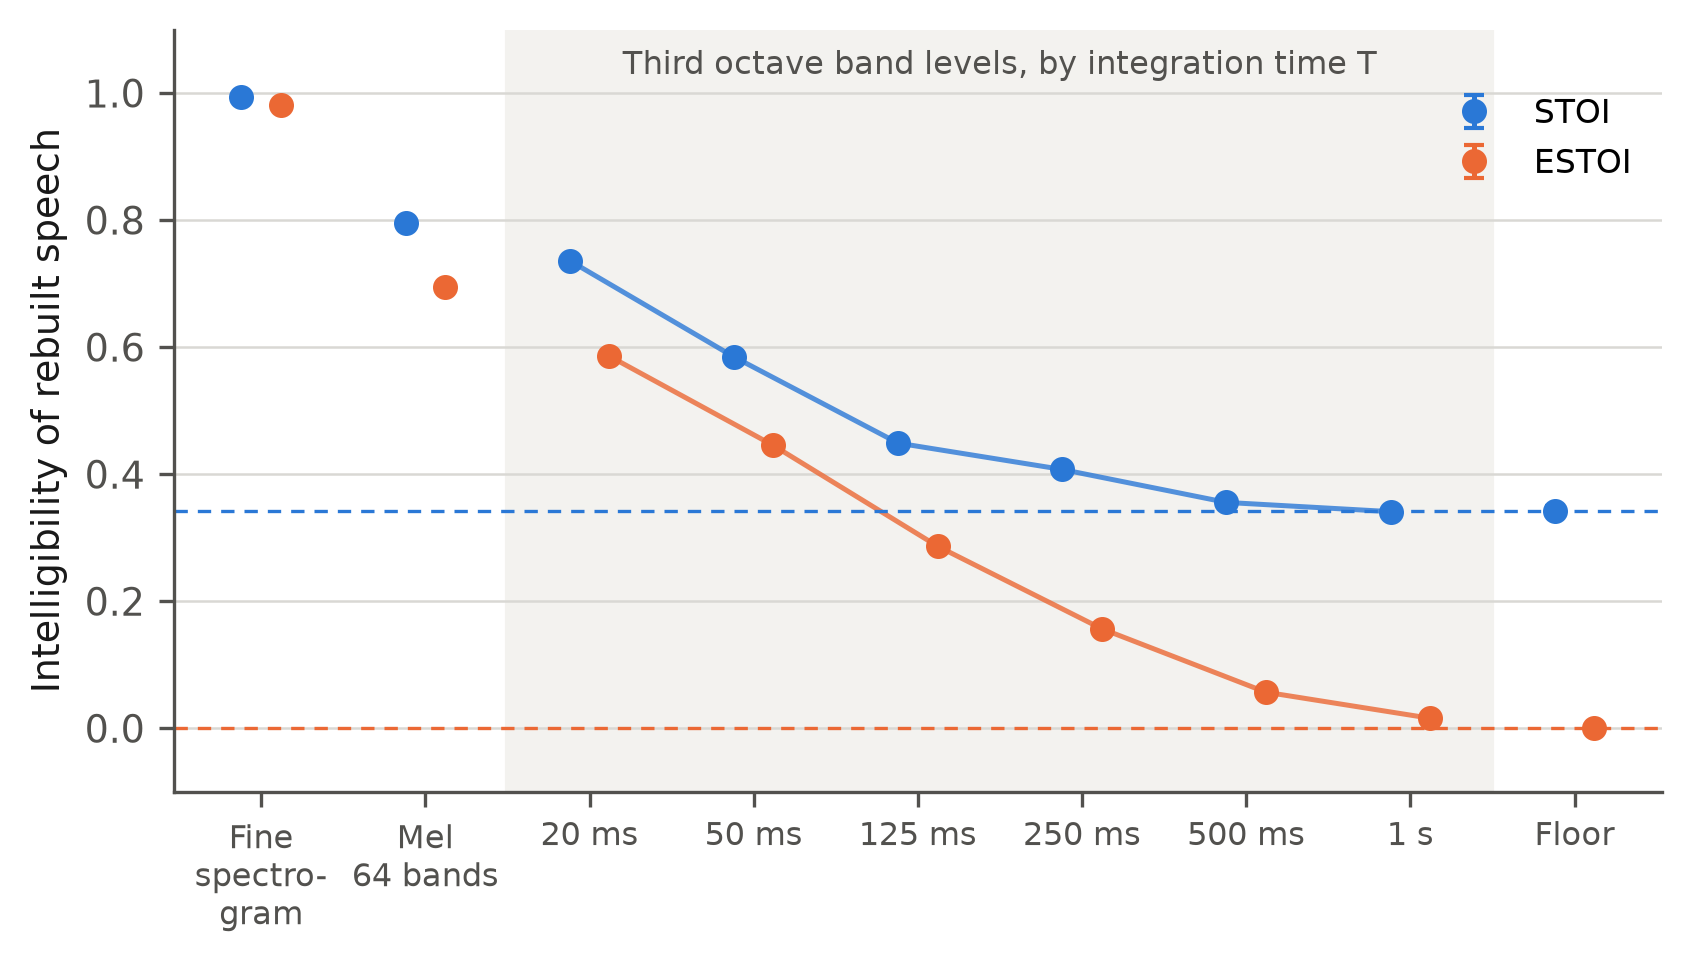

,Sensor output,Time resolution,STOI,ESTOI,ESTOI above floor (paired)
0,Fine magnitude spectrogram,8 ms,0.993 ± 0.001,0.982 ± 0.002,+0.981 ± 0.003
1,"Mel spectrogram, 64 bands",32 ms,0.796 ± 0.004,0.694 ± 0.006,+0.694 ± 0.006
2,Third octave band levels,20 ms,0.736 ± 0.004,0.586 ± 0.006,+0.585 ± 0.006
3,Third octave band levels,50 ms,0.585 ± 0.004,0.445 ± 0.006,+0.445 ± 0.006
4,Third octave band levels,125 ms,0.449 ± 0.005,0.287 ± 0.006,+0.286 ± 0.006
5,Third octave band levels,250 ms,0.407 ± 0.006,0.157 ± 0.005,+0.156 ± 0.005
6,Third octave band levels,500 ms,0.356 ± 0.006,0.057 ± 0.004,+0.056 ± 0.004
7,Third octave band levels,1 s,0.341 ± 0.006,0.016 ± 0.002,+0.015 ± 0.003
8,Floor: noise with long term spectrum,None,0.342 ± 0.007,0.001 ± 0.002,0


In [21]:
def ci(x):
    x = np.asarray(x, float)
    return x.mean(), stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))


KEYS_A = ["R1_fine_mag", "R2_mel64_32ms"] + [f"R3_tob_{t}ms" for t in (20, 50, 125, 250, 500, 1000)] + ["floor_ltas_noise"]
SA = {}
for k in KEYS_A:
    st = np.array([r[k][0] for r in RA_]); es = np.array([r[k][1] for r in RA_])
    SA[k] = dict(stoi=ci(st), estoi=ci(es), st=st, es=es)
for k in KEYS_A[:-1]:
    dst, des = SA[k]["st"] - SA["floor_ltas_noise"]["st"], SA[k]["es"] - SA["floor_ltas_noise"]["es"]
    SA[k].update(dstoi=ci(dst), destoi=ci(des), wilcoxon_p=float(stats.wilcoxon(des).pvalue))
TMIN = None
for t in (20, 50, 125, 250, 500, 1000):
    a = SA[f"R3_tob_{t}ms"]
    if sum(a["dstoi"]) <= 0.05 and sum(a["destoi"]) <= 0.05:
        TMIN = t; break
print("Shortest integration time within 0.05 of the floor (upper 95% bound):", TMIN, "ms")

labels_a = ["Fine\nspectro-\ngram", "Mel\n64 bands", "20 ms", "50 ms", "125 ms", "250 ms", "500 ms", "1 s", "Floor"]
fig, ax = plt.subplots(figsize=(6.4, 3.3))
x = np.arange(len(KEYS_A))
for off, met, col, lab in [(-0.12, "stoi", BLUE, "STOI"), (0.12, "estoi", ORANGE, "ESTOI")]:
    mm = [SA[k][met][0] for k in KEYS_A]; hh = [SA[k][met][1] for k in KEYS_A]
    ax.errorbar(x + off, mm, yerr=hh, fmt="o", ms=5, color=col, ecolor=col, elinewidth=1.2, capsize=2.5, label=lab, zorder=3)
    ax.plot(x[2:8] + off, mm[2:8], color=col, lw=1.2, alpha=0.8, zorder=2)
ax.axhline(SA["floor_ltas_noise"]["stoi"][0], color=BLUE, lw=0.8, ls=(0, (4, 3)))
ax.axhline(SA["floor_ltas_noise"]["estoi"][0], color=ORANGE, lw=0.8, ls=(0, (4, 3)))
ax.axvspan(1.5, 7.5, color="#f3f2ef", zorder=0)
ax.text(4.5, 1.03, "Third octave band levels, by integration time T", ha="center", fontsize=7.8, color=INK2)
ax.set_xticks(x); ax.set_xticklabels(labels_a, fontsize=7.6)
ax.set_ylabel("Intelligibility of rebuilt speech"); ax.set_ylim(-0.1, 1.1)
ax.yaxis.grid(True, color=GRID, lw=0.6, zorder=0)
ax.legend(frameon=False, fontsize=8, loc="upper right", bbox_to_anchor=(1.0, 0.95))
save(fig, "figure7_expA.png")

t6 = []
lab6 = {"R1_fine_mag": ("Fine magnitude spectrogram", "8 ms"), "R2_mel64_32ms": ("Mel spectrogram, 64 bands", "32 ms"),
        "floor_ltas_noise": ("Floor: noise with long term spectrum", "None")}
for t in (20, 50, 125, 250, 500, 1000):
    lab6[f"R3_tob_{t}ms"] = ("Third octave band levels", "1 s" if t == 1000 else f"{t} ms")
for k in KEYS_A:
    a = SA[k]
    t6.append([lab6[k][0], lab6[k][1], f"{a['stoi'][0]:.3f} ± {a['stoi'][1]:.3f}", f"{a['estoi'][0]:.3f} ± {a['estoi'][1]:.3f}",
               (f"{a['destoi'][0]:+.3f} ± {a['destoi'][1]:.3f}".replace("-", "−") if "destoi" in a else "0")])
TAB6 = pd.DataFrame(t6, columns=["Sensor output", "Time resolution", "STOI", "ESTOI", "ESTOI above floor (paired)"])
TAB6.to_csv(TAB / "table6_expA.csv", index=False)
display(TAB6)

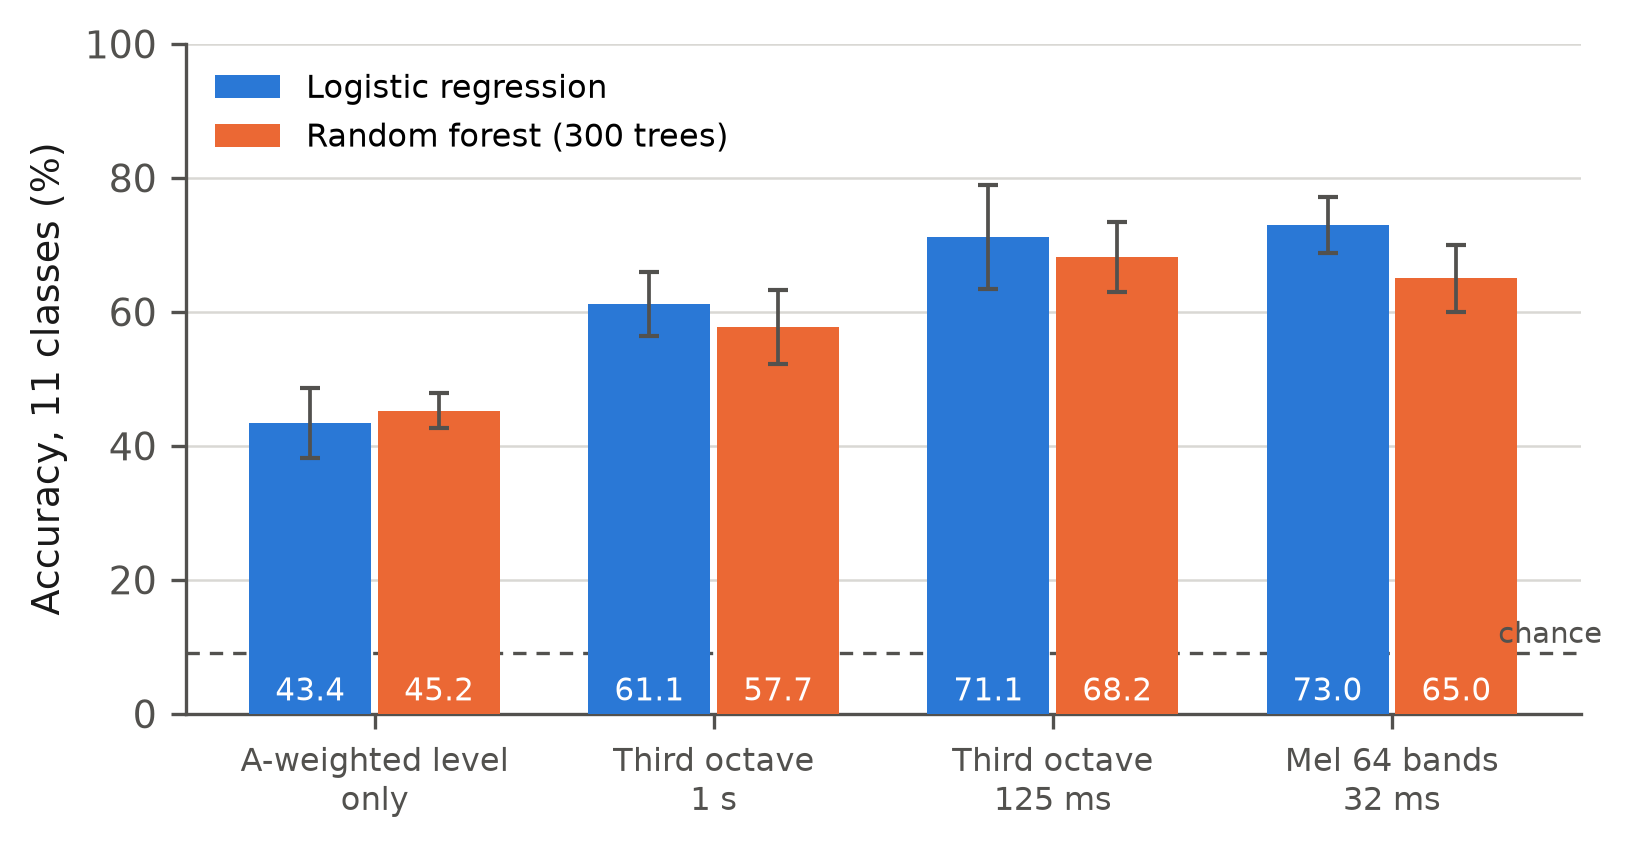

In [22]:
reps_b = ["laeq_only", "tob_1s", "tob_125ms", "mel64_32ms"]
rl = ["A-weighted level\nonly", "Third octave\n1 s", "Third octave\n125 ms", "Mel 64 bands\n32 ms"]
fig, ax = plt.subplots(figsize=(6.0, 2.9))
x = np.arange(len(reps_b)); w = 0.36
for off, mname, col, lab in [(-w / 2 - 0.01, "logreg", BLUE, "Logistic regression"), (w / 2 + 0.01, "rf", ORANGE, "Random forest (300 trees)")]:
    mm = [RB_[f"{r}|{mname}"]["acc_mean"] * 100 for r in reps_b]; ss = [RB_[f"{r}|{mname}"]["acc_sd"] * 100 for r in reps_b]
    bars = ax.bar(x + off, mm, w, color=col, label=lab, zorder=3, yerr=ss, error_kw=dict(ecolor=INK2, lw=0.9, capsize=2.5))
    for b_, v in zip(bars, mm):
        ax.text(b_.get_x() + b_.get_width() / 2, 2, f"{v:.1f}", ha="center", fontsize=7.4, color="white", zorder=4)
ax.axhline(100 / 11, color=INK2, lw=0.8, ls=(0, (4, 3)))
ax.text(3.62, 100 / 11 + 1.5, "chance", fontsize=7, color=INK2, ha="right")
ax.set_xticks(x); ax.set_xticklabels(rl, fontsize=7.8)
ax.set_ylabel("Accuracy, 11 classes (%)"); ax.set_ylim(0, 100)
ax.yaxis.grid(True, color=GRID, lw=0.6, zorder=0)
ax.legend(frameon=False, fontsize=7.8, loc="upper left")
save(fig, "figure8_expB.png")

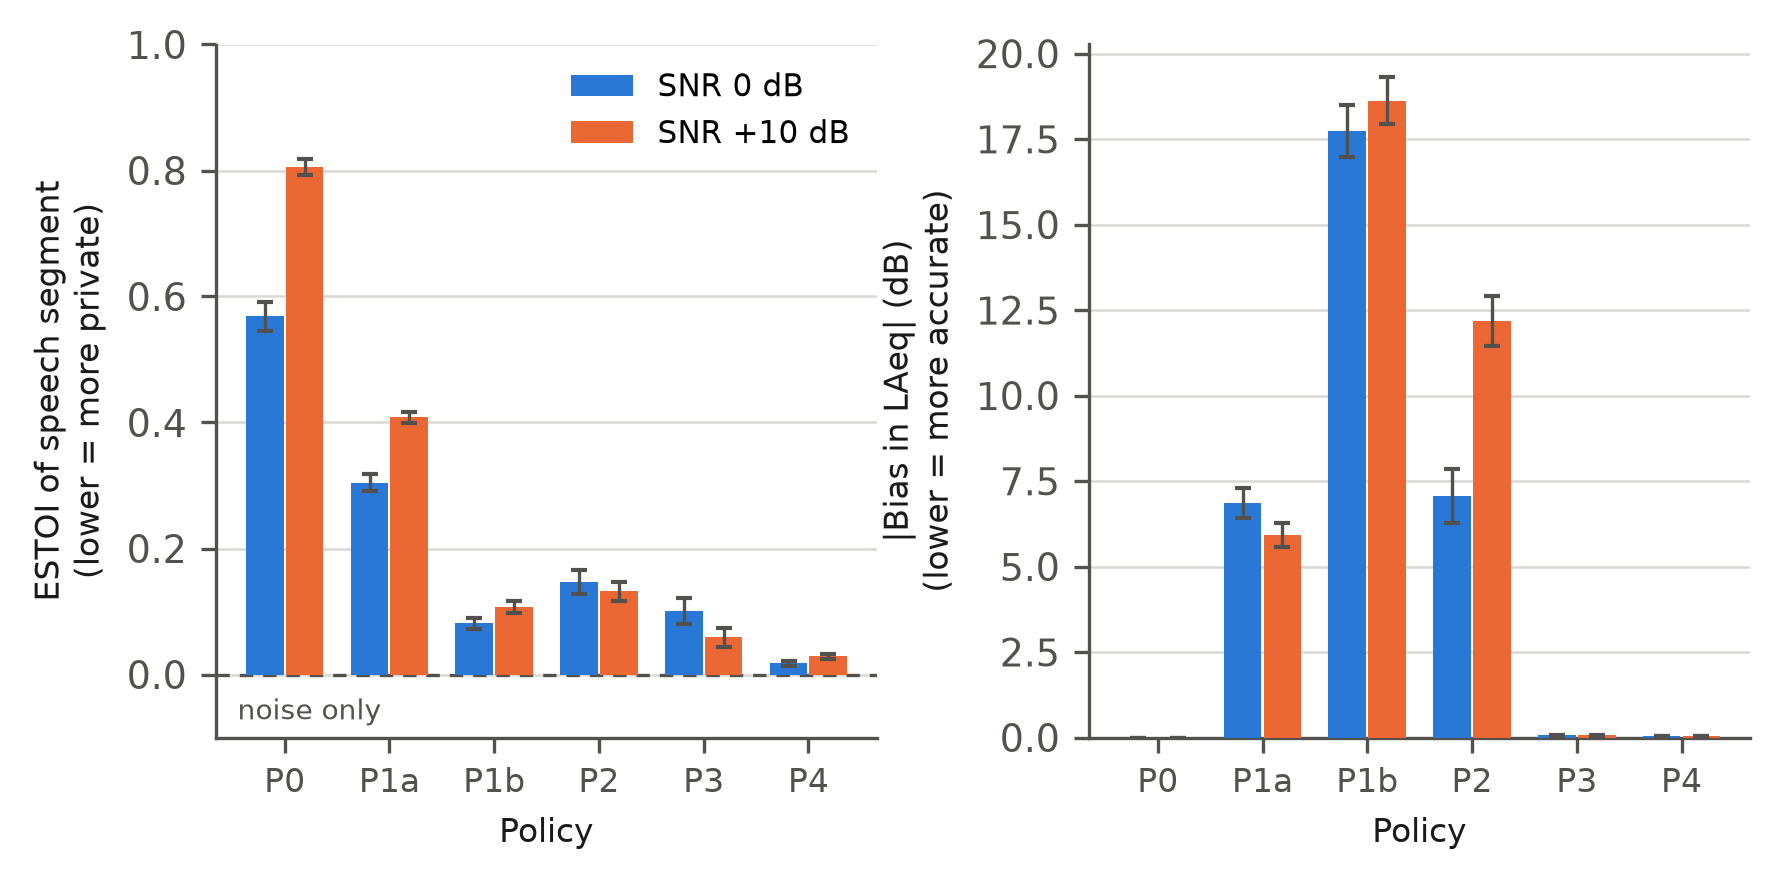

,Policy,Frames redacted (%),"ESTOI, 0 dB","LAeq bias (dB), 0 dB","ESTOI, +10 dB","LAeq bias (dB), +10 dB","Band error 0.5 to 4 kHz (dB), +10 dB"
0,P0 None,0,0.57,0.00,0.81,0.00,0.00
1,"P1a Fixed, 0.5 to 4 kHz",100,0.30,−6.86,0.41,−5.92,38.98
2,"P1b Fixed, 0.15 to 5 kHz",100,0.08,−17.74,0.11,−18.63,48.93
3,P2 Adaptive removal,68,0.15,−7.06,0.13,−12.18,18.11
4,"P3 Adaptive, level preserving",68,0.10,−0.06,0.06,−0.05,0.06
5,"P4 Oracle, level preserving",68,0.02,−0.04,0.03,−0.04,0.05
6,Noise only (reference),,0.00,,0.00,,


Detector: {0: {'recall': 0.684, 'precision': 0.894, 'fpr': 0.123}, 10: {'recall': 0.875, 'precision': 0.918, 'fpr': 0.12}}
Per class LAeq bias (dB):
              P0_none  P1a_fixed_500_4k  P1b_fixed_150_5k  P2_adaptive_zero  P3_adaptive_substitute  P4_oracle_substitute
airplane          0.0             -5.27            -18.82            -10.50                   -0.02                 -0.01
car_horn          0.0             -8.61            -20.26            -10.57                   -0.07                 -0.04
chainsaw          0.0             -6.05            -14.78             -8.40                   -0.05                 -0.04
church_bells      0.0             -6.94            -21.68             -8.12                   -0.07                 -0.05
engine            0.0             -6.70            -17.95             -8.40                   -0.07                 -0.04
fireworks         0.0             -5.74            -17.07            -13.43                   -0.05                 -0.

In [23]:
rows_c = RC_["rows"]
SC = {}
for snr in (0, 10):
    rr = [r for r in rows_c if r["snr"] == snr]; SC[snr] = {}
    for p in POLICIES:
        d = {m: ci([r[p][m] for r in rr]) for m in ("stoi", "estoi")}
        d["abs_dLAeq"] = ci([abs(r[p]["dLAeq"]) for r in rr]); d["dLAeq"] = ci([r[p]["dLAeq"] for r in rr])
        d["band_mae"] = ci([r[p]["band_mae_500_4k"] for r in rr]); d["frac"] = float(np.mean([r[p]["frac_frames_redacted"] for r in rr]))
        SC[snr][p] = d
    SC[snr]["floor_estoi"] = ci([r["floor_estoi"] for r in rr]); SC[snr]["floor_stoi"] = ci([r["floor_stoi"] for r in rr])
    tp, fp, fn, tn = (sum(r[k] for r in rr) for k in ("det_tp", "det_fp", "det_fn", "det_tn"))
    SC[snr]["det"] = dict(recall=tp / (tp + fn), precision=tp / (tp + fp), fpr=fp / (fp + tn))
    SC[snr]["n"] = len(rr)
CLS_C = sorted(set(r["cls"] for r in rows_c))
PERCLASS = {c: {p: float(np.mean([r[p]["dLAeq"] for r in rows_c if r["cls"] == c])) for p in POLICIES} for c in CLS_C}

pl = ["P0", "P1a", "P1b", "P2", "P3", "P4"]
fig, axes = plt.subplots(1, 2, figsize=(6.6, 3.0), gridspec_kw=dict(wspace=0.32))
x = np.arange(len(POLICIES)); w = 0.36
for ax, met, yl, ylim in [(axes[0], "estoi", "ESTOI of speech segment\n(lower = more private)", (-0.1, 1.0)),
                          (axes[1], "abs_dLAeq", "|Bias in LAeq| (dB)\n(lower = more accurate)", (0, None))]:
    for off, snr, col, lab in [(-w / 2 - 0.01, 0, BLUE, "SNR 0 dB"), (w / 2 + 0.01, 10, ORANGE, "SNR +10 dB")]:
        mm = [SC[snr][p][met][0] for p in POLICIES]; hh = [SC[snr][p][met][1] for p in POLICIES]
        ax.bar(x + off, mm, w, color=col, label=lab, zorder=3, yerr=hh, error_kw=dict(ecolor=INK2, lw=0.8, capsize=2))
    if met == "estoi":
        ax.axhline(SC[0]["floor_estoi"][0], color=INK2, lw=0.8, ls=(0, (4, 3)))
        ax.text(-0.45, SC[0]["floor_estoi"][0] - 0.07, "noise only", fontsize=6.8, color=INK2, ha="left")
    ax.set_xticks(x); ax.set_xticklabels(pl, fontsize=8); ax.set_xlabel("Policy", fontsize=8); ax.set_ylabel(yl, fontsize=8)
    if ylim[1]:
        ax.set_ylim(*ylim)
    ax.yaxis.grid(True, color=GRID, lw=0.6, zorder=0)
axes[0].legend(frameon=False, fontsize=7.4, loc="upper right")
save(fig, "figure9_expC.png")


def sgn(v):
    s = f"{v:+.2f}"
    return "0.00" if s in ("-0.00", "+0.00") else s.replace("-", "−")


pnames = {"P0_none": "P0 None", "P1a_fixed_500_4k": "P1a Fixed, 0.5 to 4 kHz", "P1b_fixed_150_5k": "P1b Fixed, 0.15 to 5 kHz",
          "P2_adaptive_zero": "P2 Adaptive removal", "P3_adaptive_substitute": "P3 Adaptive, level preserving",
          "P4_oracle_substitute": "P4 Oracle, level preserving"}
t7 = [[pnames[p], f"{SC[10][p]['frac'] * 100:.0f}", f"{SC[0][p]['estoi'][0]:.2f}", sgn(SC[0][p]["dLAeq"][0]),
       f"{SC[10][p]['estoi'][0]:.2f}", sgn(SC[10][p]["dLAeq"][0]), f"{SC[10][p]['band_mae'][0]:.2f}"] for p in POLICIES]
t7.append(["Noise only (reference)", "", r2(SC[0]["floor_estoi"][0]), "", r2(SC[10]["floor_estoi"][0]), "", ""])
TAB7 = pd.DataFrame(t7, columns=["Policy", "Frames redacted (%)", "ESTOI, 0 dB", "LAeq bias (dB), 0 dB", "ESTOI, +10 dB",
                                 "LAeq bias (dB), +10 dB", "Band error 0.5 to 4 kHz (dB), +10 dB"])
TAB7.to_csv(TAB / "table7_expC.csv", index=False)
display(TAB7)
print("Detector:", {s: {k: round(v, 3) for k, v in SC[s]["det"].items()} for s in (0, 10)})
print("Per class LAeq bias (dB):")
print(pd.DataFrame(PERCLASS).T.round(2).to_string())

## Part 5. Control framework (Figure 6)

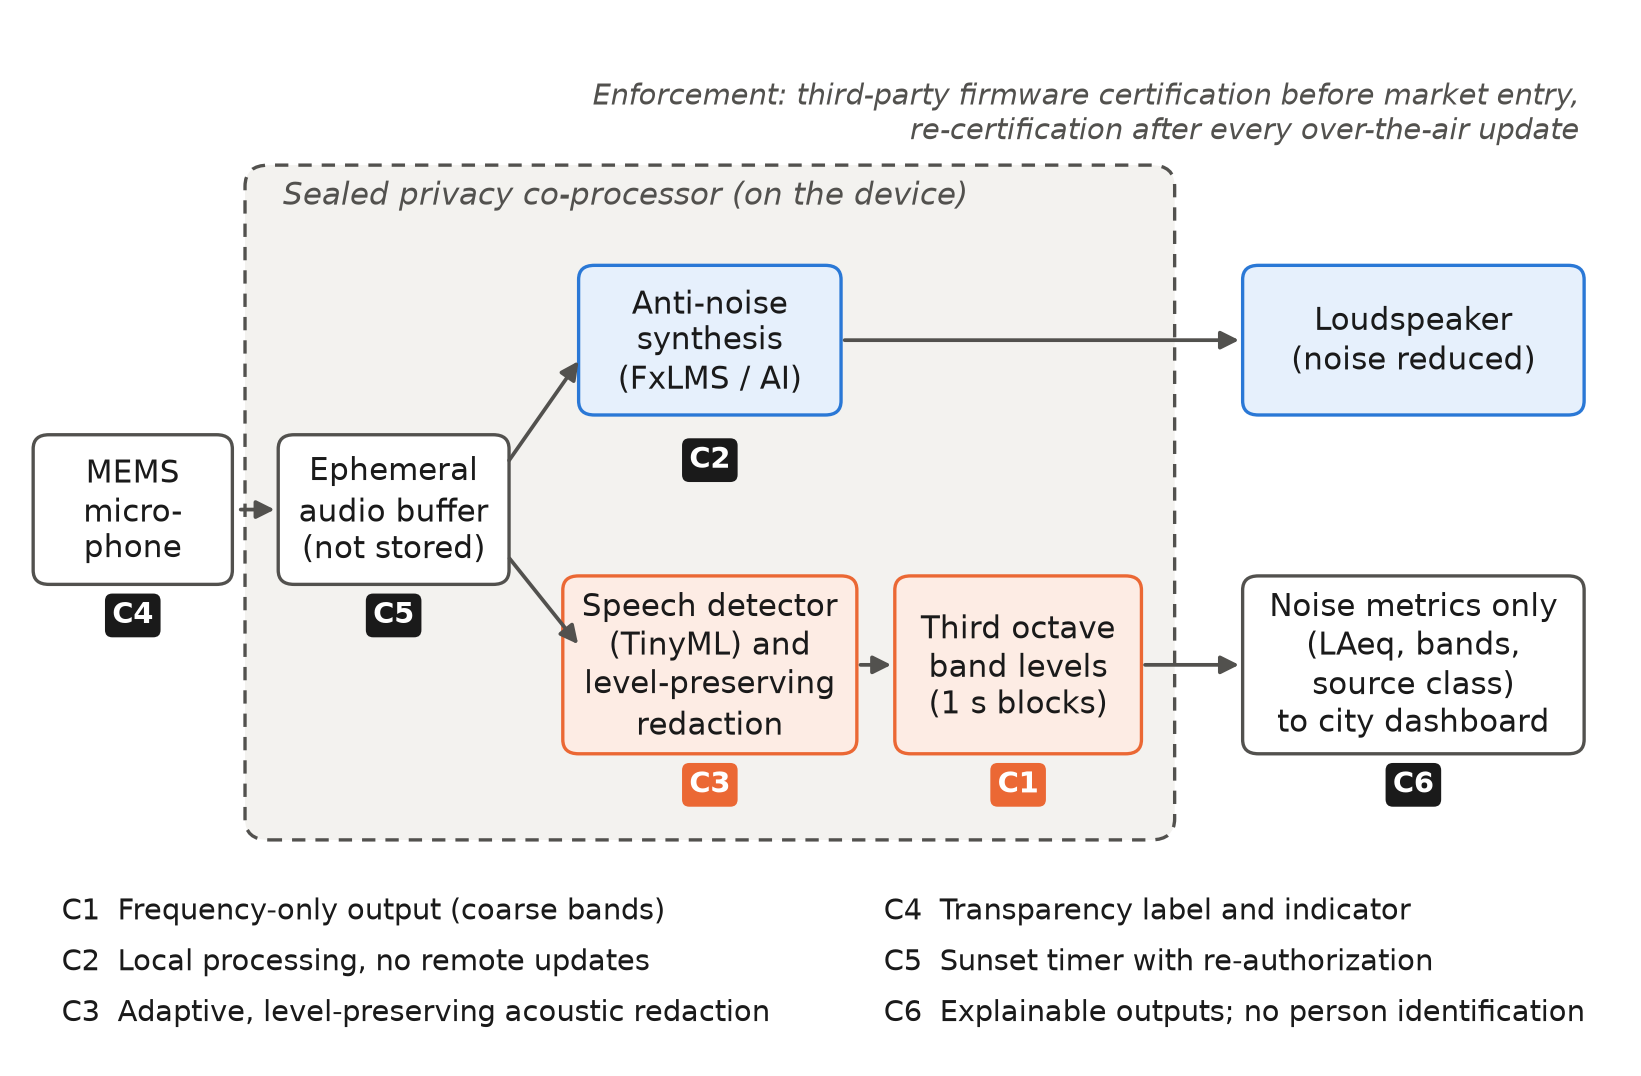

In [24]:
fig, ax = plt.subplots(figsize=(6.8, 4.4))
ax.set_xlim(0, 100); ax.set_ylim(0, 72); ax.axis("off")
BLUE_L, ORANGE_L, GREY_L = "#e6f0fc", "#fdece4", "#f3f2ef"


def fbox(x, y, w, h, t, fc="white", ec=INK2, fs=7.4):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.3,rounding_size=1.0", fc=fc, ec=ec, lw=0.8))
    ax.text(x + w / 2, y + h / 2, t, ha="center", va="center", fontsize=fs, color=INK, linespacing=1.25)


def farr(x0, y0, x1, y1):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", color=INK2, lw=0.9))


def ftag(x, y, t, c):
    ax.text(x, y, t, ha="center", va="center", fontsize=7, color="white", fontweight="bold", bbox=dict(boxstyle="round,pad=0.25", fc=c, ec="none"))


ax.add_patch(FancyBboxPatch((14, 15), 58, 47, boxstyle="round,pad=0.4,rounding_size=1.5", fc=GREY_L, ec=INK2, lw=0.8, ls=(0, (4, 3))))
ax.text(16, 59.6, "Sealed privacy co-processor (on the device)", fontsize=7.4, color=INK2, style="italic")
fbox(0.5, 33, 12, 10, "MEMS\nmicro-\nphone"); farr(12.8, 38, 16, 38)
fbox(16, 33, 14, 10, "Ephemeral\naudio buffer\n(not stored)")
farr(30, 41, 35, 49); fbox(35, 45, 16, 10, "Anti-noise\nsynthesis\n(FxLMS / AI)", fc=BLUE_L, ec=BLUE)
farr(51, 50, 77, 50); fbox(77, 45, 21, 10, "Loudspeaker\n(noise reduced)", fc=BLUE_L, ec=BLUE)
farr(30, 35, 35, 28); fbox(34, 21, 18, 12, "Speech detector\n(TinyML) and\nlevel-preserving\nredaction", fc=ORANGE_L, ec=ORANGE)
farr(52, 27, 55, 27); fbox(55, 21, 15, 12, "Third octave\nband levels\n(1 s blocks)", fc=ORANGE_L, ec=ORANGE)
farr(70, 27, 77, 27); fbox(77, 21, 21, 12, "Noise metrics only\n(LAeq, bands,\nsource class)\nto city dashboard")
for (xx, yy, t, c) in [(43, 41.5, "C2", INK), (43, 18.5, "C3", ORANGE), (62.5, 18.5, "C1", ORANGE), (87.5, 18.5, "C6", INK),
                       (6.5, 30.5, "C4", INK), (23, 30.5, "C5", INK)]:
    ftag(xx, yy, t, c)
for i, t in enumerate(["C1  Frequency-only output (coarse bands)", "C2  Local processing, no remote updates",
                       "C3  Adaptive, level-preserving acoustic redaction", "C4  Transparency label and indicator",
                       "C5  Sunset timer with re-authorization", "C6  Explainable outputs; no person identification"]):
    ax.text(2 + (i // 3) * 52, 9.5 - (i % 3) * 3.6, t, fontsize=6.9, color=INK, va="center")
ax.text(98, 66, "Enforcement: third-party firmware certification before market entry,\nre-certification after every over-the-air update",
        fontsize=6.9, color=INK2, ha="right", va="center", style="italic")
save(fig, "figure6_framework.png")

## Part 6. Every number quoted in the paper, and a check against the paper

The values below are written to `results/paper_values.json`. The last cell compares this run with the frozen copies in `data/expected/`, which hold what is printed in the submitted paper: every quoted value (`paper_values.json`), every table (`tables/`), and every figure (`figures/`). How the comparison treats floating point differences is explained just before the last cell.

In [25]:
A_ = {k: SA[k] for k in KEYS_A}
PV["A_N"] = len(RA_)
for k, tag in [("R1_fine_mag", "R1"), ("R2_mel64_32ms", "R2"), ("floor_ltas_noise", "FLOOR")] + [(f"R3_tob_{t}ms", f"T{t}") for t in (20, 50, 125, 250, 500, 1000)]:
    PV[f"A_{tag}_STOI"] = r2(A_[k]["stoi"][0]); PV[f"A_{tag}_ESTOI"] = r2(A_[k]["estoi"][0])
    if "destoi" in A_[k]:
        PV[f"A_{tag}_DES"] = f"{A_[k]['destoi'][0]:.2f}, 95% CI ±{A_[k]['destoi'][1]:.2f}"
PV["A_TMIN_MS"] = TMIN
g = lambda k: RB_[k]["acc_mean"] * 100
PV.update(B_LAEQ_BEST=f"{max(g('laeq_only|logreg'), g('laeq_only|rf')):.1f}", B_TOB1_LR=f"{g('tob_1s|logreg'):.1f}",
          B_TOB1_RF=f"{g('tob_1s|rf'):.1f}", B_TOB125_LR=f"{g('tob_125ms|logreg'):.1f}", B_TOB125_RF=f"{g('tob_125ms|rf'):.1f}",
          B_MEL_LR=f"{g('mel64_32ms|logreg'):.1f}", B_MEL_RF=f"{g('mel64_32ms|rf'):.1f}",
          B_TOB1_BEST=f"{max(g('tob_1s|logreg'), g('tob_1s|rf')):.1f}",
          B_TOB1_SP_P=r2(RB_["tob_1s|rf"]["speech_precision"]), B_TOB1_SP_R=r2(RB_["tob_1s|rf"]["speech_recall"]),
          B_LR_PARAMS=f"{RB_['tob_1s|logreg']['n_params']:,}", B_LR_KB=f"{RB_['tob_1s|logreg']['n_params'] * 4 / 1024:.0f}")
PV["C_DET_PARAMS"] = RC_["detector_params"]
for s in (0, 10):
    PV[f"C_DET_REC{s}"] = f"{SC[s]['det']['recall'] * 100:.1f}"; PV[f"C_DET_FPR{s}"] = f"{SC[s]['det']['fpr'] * 100:.1f}"
for tag, p in {"P0": "P0_none", "P1A": "P1a_fixed_500_4k", "P1B": "P1b_fixed_150_5k", "P2": "P2_adaptive_zero",
               "P3": "P3_adaptive_substitute", "P4": "P4_oracle_substitute"}.items():
    for s in (0, 10):
        PV[f"C_{tag}_ES{s}"] = r2(SC[s][p]["estoi"][0]); PV[f"C_{tag}_D{s}"] = sgn(SC[s][p]["dLAeq"][0])
PV["C_FLOOR_ES10"] = r2(SC[10]["floor_estoi"][0])
PV["C_P3_BAND10"] = r2(SC[10]["P3_adaptive_substitute"]["band_mae"][0]); PV["C_P2_BAND10"] = r2(SC[10]["P2_adaptive_zero"]["band_mae"][0])
PV["C_SIREN_P1B"] = sgn(PERCLASS["siren"]["P1b_fixed_150_5k"]); PV["C_BELLS_P1B"] = sgn(PERCLASS["church_bells"]["P1b_fixed_150_5k"])
PV["C_SIREN_P3"] = sgn(PERCLASS["siren"]["P3_adaptive_substitute"]); PV["C_BELLS_P3"] = sgn(PERCLASS["church_bells"]["P3_adaptive_substitute"])
PV = {k: (int(v) if isinstance(v, (np.integer,)) else float(v) if isinstance(v, np.floating) else v) for k, v in PV.items()}
json.dump(PV, open(RES / "paper_values.json", "w"), indent=1, ensure_ascii=False)
print(len(PV), "values written to", RES / "paper_values.json")

369 values written to /content/listening-wall/results/paper_values.json


### Check against the paper

A full recompute of the experiments uses floating point arithmetic. On a different processor, the last bits of some results can change, and a value that sits exactly on a rounding boundary can then move by one unit in its last printed digit. The check below therefore puts every value and table cell in one of three groups: identical, within one unit of the last printed digit, or different. Counts and other whole numbers must be identical. Figures are compared pixel by pixel; a figure counts as matching when fewer than 0.5% of its pixels change. On the machine used for the paper every check was identical.

In [26]:
from PIL import Image
import csv
NUM = re.compile(r"[−-]?\d[\d,]*(?:\.\d+)?")


def last_digit_close(a, b):
    """True when two printed values differ only by one unit in the last printed decimal."""
    a, b = str(a), str(b)
    na, nb = NUM.findall(a), NUM.findall(b)
    if NUM.sub("#", a) != NUM.sub("#", b) or len(na) != len(nb):
        return False
    for x, y in zip(na, nb):
        if x == y:
            continue
        dx = len(x.split(".")[1]) if "." in x else 0
        dy = len(y.split(".")[1]) if "." in y else 0
        if dx != dy or dx == 0:
            return False
        fx, fy = (float(v.replace("−", "-").replace(",", "")) for v in (x, y))
        if abs(fx - fy) > 1.0001 * 10 ** -dx:
            return False
    return True


EXPD = ROOT / "data" / "expected"
if (EXPD / "paper_values.json").exists():
    EXP = json.load(open(EXPD / "paper_values.json"))
    same = [k for k in EXP if str(EXP[k]) == str(PV.get(k))]
    near = [k for k in EXP if k not in same and last_digit_close(EXP[k], PV.get(k))]
    diff = [k for k in EXP if k not in same and k not in near]
    print(f"Values printed in the paper: {len(EXP)} checked, {len(same)} identical, "
          f"{len(near)} within one unit of the last digit, {len(diff)} different.")
    for k in near + diff:
        print(f"  {k}: paper {EXP[k]}  this run {PV.get(k)}")
else:
    print("No frozen copy of the paper values found.")

if (EXPD / "tables").exists():
    tabs = sorted((EXPD / "tables").glob("*.csv"))
    n_same = n_near = 0
    for p in tabs:
        q = TAB / p.name
        if q.exists() and q.read_bytes() == p.read_bytes():
            n_same += 1
            continue
        ra = list(csv.reader(open(p, newline="", encoding="utf-8")))
        rb = list(csv.reader(open(q, newline="", encoding="utf-8"))) if q.exists() else []
        cells = [(x, y) for r1, r2_ in zip(ra, rb) for x, y in zip(r1, r2_) if x != y]
        if len(ra) == len(rb) and all(len(r1) == len(r2_) for r1, r2_ in zip(ra, rb)) and all(last_digit_close(x, y) for x, y in cells):
            n_near += 1
            print(f"  {p.name}: {len(cells)} cells within one unit of the last digit")
        else:
            print(f"  {p.name}: different")
    print(f"Tables: {len(tabs)} checked, {n_same} identical, {n_near} within one unit of the last digit, "
          f"{len(tabs) - n_same - n_near} different.")

if (EXPD / "figures").exists():
    figs = sorted((EXPD / "figures").glob("*.png"))
    n_same = n_near = 0
    for p in figs:
        a = np.asarray(Image.open(p).convert("RGB"), dtype=np.int16)
        b = np.asarray(Image.open(FIG / p.name).convert("RGB"), dtype=np.int16)
        if a.shape != b.shape:
            print(f"  {p.name}: different size, paper {a.shape[1]} x {a.shape[0]}, this run {b.shape[1]} x {b.shape[0]}")
            continue
        share = (a != b).any(axis=2).mean() * 100
        if share == 0:
            n_same += 1
        elif share < 0.5:
            n_near += 1
            print(f"  {p.name}: matches, {share:.3f}% of pixels changed")
        else:
            print(f"  {p.name}: different, {share:.3f}% of pixels changed")
    print(f"Figures: {len(figs)} checked, {n_same} identical, {n_near} matching with under 0.5% of pixels changed, "
          f"{len(figs) - n_same - n_near} different.")

Values printed in the paper: 369 checked, 369 identical, 0 within one unit of the last digit, 0 different.
Tables: 7 checked, 7 identical, 0 within one unit of the last digit, 0 different.


Figures: 9 checked, 9 identical, 0 matching with under 0.5% of pixels changed, 0 different.
